# 03 — Generador C-VAE condicional (familia + pitch)

**Proyecto Final — Inteligencia Artificial II (UNCuyo)**  
**Alumno:** Enzo Palau (Legajo 13686)

## Objetivo

Entrenar un autoencoder variacional convolucional condicional (C-VAE) que genere espectrogramas mel `128×128` de notas de instrumentos a partir de:

- familia de instrumento (`brass`, `guitar`, `keyboard`, `string`);
- pitch MIDI (36–84);
- ruido latente `z ~ N(0, I)`.

Este notebook cubre el **hito 3** del cronograma: VAE y primeras evaluaciones. El juez AST **no se usa acá**; sus muestras generadas se guardan para el notebook de evaluación final (torneo VAE vs Flow Matching vs baseline). Acá usamos `train` para entrenar y `valid` para early stopping y análisis; `test` queda reservado.

## Qué se va a producir

1. Un C-VAE entrenado con curvas de pérdida y checkpoints.
2. Reconstrucciones reales vs VAE sobre `valid`.
3. Muestras generadas desde el prior para condiciones fijas.
4. Ejemplos de escucha con Griffin-Lim: real, reconstruido y generado.
5. Métricas objetivas sin juez: L1/MSE, error de pitch, diversidad y distancia tipo FID sobre features mel.
6. Espacio latente en 2D (PCA).

## 1. Configuración del entorno

### ¿Qué se hace a continuación?
Se importan las librerías, se fijan las semillas (`SEED=42`) y se detectan las rutas de datos y salida para Kaggle, Colab o local. En Kaggle se buscan los `.npz` en `/kaggle/input` (con varios nombres posibles) y se escribe en `/kaggle/working/vae_output`.

### ¿Por qué se hace?
El notebook tiene que correr sin cambios en Kaggle y, eventualmente, en local. Fijar la semilla hace reproducibles las particiones, los batches y las muestras generadas. La detección robusta de rutas evita el error más común: que el dataset esté montado con otro nombre o un nivel de carpeta más adentro.

In [1]:
import os
import sys
import json
import math
import time
import random
import warnings
import zipfile
import traceback
from pathlib import Path
from copy import deepcopy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

import librosa
import soundfile as sf
import IPython.display as ipd

warnings.filterwarnings('ignore')

# ── Semilla global ──────────────────────────────────────────────────────────
SEED = 1
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = False
torch.backends.cudnn.benchmark = True

# ── Detección de entorno ────────────────────────────────────────────────────
IN_KAGGLE = os.environ.get('KAGGLE_KERNEL_RUN_TYPE') is not None
IN_COLAB = 'google.colab' in sys.modules

def _encontrar_data_dir():
    """Busca la carpeta que contiene los .npz procesados."""
    candidatos = [
        Path('/kaggle/input/nsynth-processed-palau'),
        Path('/kaggle/input/datasets/enzopalau/nsynth-processed-palau'),
        Path('/kaggle/input/nsynth-processed'),
        Path('/content/drive/MyDrive/IA2_Proyecto_Instrumentos/processed'),
        Path('./data_processed/processed'),
        Path('../tensores'),
        Path('../../tensores'),
        Path('./tensores'),
    ]
    for p in candidatos:
        if p.exists() and any(p.glob('*.npz')):
            return p
    raiz = Path('/kaggle/input')
    if raiz.exists():
        matches = list(raiz.rglob('nsynth_processed_train.npz'))
        if matches:
            return matches[0].parent
    return Path('./data_processed/processed')

DATA_DIR = _encontrar_data_dir()

if IN_KAGGLE:
    OUTPUT_DIR = Path('/kaggle/working/vae_output')
elif IN_COLAB:
    OUTPUT_DIR = Path('/content/vae_output')
else:
    OUTPUT_DIR = Path('./vae_output')

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
AUDIO_DIR = OUTPUT_DIR / 'audio'
AUDIO_DIR.mkdir(parents=True, exist_ok=True)

print(f'[INFO] Entorno: {"Kaggle" if IN_KAGGLE else ("Colab" if IN_COLAB else "local")}')
print(f'[INFO] DATA_DIR   = {DATA_DIR}')
print(f'[INFO] OUTPUT_DIR = {OUTPUT_DIR}')
print(f'[INFO] Semilla    = {SEED}')

[INFO] Entorno: Kaggle
[INFO] DATA_DIR   = /kaggle/input/datasets/enzopalau/nsynth-processed-palau
[INFO] OUTPUT_DIR = /kaggle/working/vae_output
[INFO] Semilla    = 1


## 2. Hardware y verificación previa

### ¿Qué se hace a continuación?
Se detecta la GPU, se definen las constantes del problema y se cargan los splits `train` y `valid` desde los `.npz`. Antes de seguir se verifican shapes, dtypes, rangos, familias y ausencia de NaN/Inf.

### ¿Por qué se hace?
Entrenar 40 minutos para descubrir que un tensor tenía otra forma o un valor corrupto es exactamente lo que queremos evitar. Esta verificación cuesta segundos y deja el terreno limpio. El split `test` no se carga: se reserva para la evaluación final.

In [2]:
# ── Dispositivo ─────────────────────────────────────────────────────────────
if torch.cuda.is_available():
    device = torch.device('cuda:0')
    print(f'[INFO] GPU: {torch.cuda.get_device_name(0)}')
    print(f'[INFO] GPUs visibles: {torch.cuda.device_count()}')
    print(f'[INFO] VRAM: {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')
else:
    device = torch.device('cpu')
    print('[ADVERTENCIA] No hay GPU. Se usará CPU (mucho más lento).')

use_amp = (device.type == 'cuda')
print(f'[INFO] Dispositivo: {device} | AMP: {use_amp}')

# ── Constantes del problema ─────────────────────────────────────────────────
FAMILY_NAMES = ['brass', 'guitar', 'keyboard', 'string']
NUM_FAMILIES = len(FAMILY_NAMES)
PITCH_MIN = 36
PITCH_MAX = 84
NUM_PITCHES = PITCH_MAX - PITCH_MIN + 1
IMG_SIZE = 128

# ── Carga robusta de un split ───────────────────────────────────────────────
def cargar_split(nombre_split):
    alias = {'val': 'valid'}
    split_real = alias.get(nombre_split, nombre_split)
    candidatos = [
        DATA_DIR / f'nsynth_processed_{split_real}.npz',
        DATA_DIR / f'nsynth_processed_{nombre_split}.npz',
        DATA_DIR / f'{split_real}.npz',
        DATA_DIR / f'{nombre_split}.npz',
    ]
    ruta = next((p for p in candidatos if p.exists()), None)
    if ruta is None:
        matches = list(DATA_DIR.rglob(f'nsynth_processed_{split_real}.npz'))
        ruta = matches[0] if matches else None
    if ruta is None:
        raise FileNotFoundError(
            f'No se encontró el split "{nombre_split}" en {DATA_DIR}. '
            f'Archivos .npz presentes: {[p.name for p in DATA_DIR.glob("*.npz")]}'
        )

    datos = np.load(ruta)
    mels = datos['mels'].astype(np.float32)
    families = datos['families'].astype(np.int64)
    pitches = datos['pitches'].astype(np.int64)

    if mels.ndim == 3:
        mels = mels[:, None, :, :]
    assert mels.shape[1:] == (1, IMG_SIZE, IMG_SIZE), f'Shape inesperada: {mels.shape}'
    assert np.isfinite(mels).all(), 'Hay NaN/Inf en los espectrogramas'
    assert families.min() >= 0 and families.max() < NUM_FAMILIES
    assert pitches.min() >= PITCH_MIN and pitches.max() <= PITCH_MAX

    X = torch.from_numpy(mels)
    y = torch.from_numpy(families)
    p = torch.from_numpy(pitches)
    print(f'[INFO] {nombre_split:5s} -> {ruta.name} | X={tuple(X.shape)} | '
          f'familias={np.bincount(families, minlength=NUM_FAMILIES).tolist()} | '
          f'rango=[{mels.min():.3f}, {mels.max():.3f}]')
    return X, y, p, ruta

X_train, y_train, p_train, ruta_train = cargar_split('train')
X_val, y_val, p_val, ruta_val = cargar_split('valid')

# test NO se carga: queda reservado para el notebook de evaluación final.
print('[INFO] test reservado para el notebook del torneo (no se toca acá).')

assert len(X_train) > 0 and len(X_val) > 0
assert set(y_train.unique().tolist()) == set(range(NUM_FAMILIES))
assert set(y_val.unique().tolist()) == set(range(NUM_FAMILIES))
print('[OK] Verificación previa completada.')

[INFO] GPU: Tesla T4
[INFO] GPUs visibles: 2
[INFO] VRAM: 15.6 GB
[INFO] Dispositivo: cuda:0 | AMP: True
[INFO] train -> nsynth_processed_train.npz | X=(18000, 1, 128, 128) | familias=[4500, 4500, 4500, 4500] | rango=[-1.000, 1.000]
[INFO] valid -> nsynth_processed_valid.npz | X=(2297, 1, 128, 128) | familias=[704, 827, 170, 596] | rango=[-1.000, 1.000]
[INFO] test reservado para el notebook del torneo (no se toca acá).
[OK] Verificación previa completada.


## 3. DataLoaders y condicionamiento

### ¿Qué se hace a continuación?
Se envuelven los tensores en `TensorDataset` y se crean los `DataLoader` de `train` y `valid`. Cada muestra devuelve `(mel, familia, pitch)`. En `train` se mezcla y se descarta el último batch incompleto; en `valid` no se mezcla.

### ¿Por qué se hace?
Como los tensores ya están en RAM, no hace falta leer audio ni usar workers: `num_workers=0` evita problemas de multiprocessing en Kaggle. `drop_last=True` mantiene batches de tamaño fijo, lo que estabiliza BatchNorm y el entrenamiento con AMP.

In [3]:
BATCH_SIZE = 64

ds_train = TensorDataset(X_train, y_train, p_train)
ds_val = TensorDataset(X_val, y_val, p_val)

loader_train = DataLoader(
    ds_train, batch_size=BATCH_SIZE, shuffle=True,
    drop_last=True, num_workers=0, pin_memory=use_amp,
)
loader_val = DataLoader(
    ds_val, batch_size=BATCH_SIZE, shuffle=False,
    drop_last=False, num_workers=0, pin_memory=use_amp,
)

print(f'[INFO] Batches train: {len(loader_train)} | Batches valid: {len(loader_val)}')
xb, fb, pb = next(iter(loader_train))
print(f'[INFO] Batch ejemplo: x={tuple(xb.shape)} | family={tuple(fb.shape)} | pitch={tuple(pb.shape)}')
print(f'[INFO] Rango del batch: [{xb.min():.3f}, {xb.max():.3f}]')

[INFO] Batches train: 281 | Batches valid: 36
[INFO] Batch ejemplo: x=(64, 1, 128, 128) | family=(64,) | pitch=(64,)
[INFO] Rango del batch: [-1.000, 1.000]


## 4. Inspección visual y cobertura de condiciones

### ¿Qué se hace a continuación?
Se grafican muestras de `train` (2 por familia) y se resume la distribución de familias, pitches y la cobertura cruzada familia×pitch.

### ¿Por qué se hace?
Antes de entrenar un generador condicional hay que confirmar que el espacio de condiciones está cubierto. Si alguna familia no tiene suficientes pitches, el VAE no podrá aprender esa región y el error de pitch se disparará ahí. También sirve como sanity-check de que los espectrogramas tienen la orientación correcta.

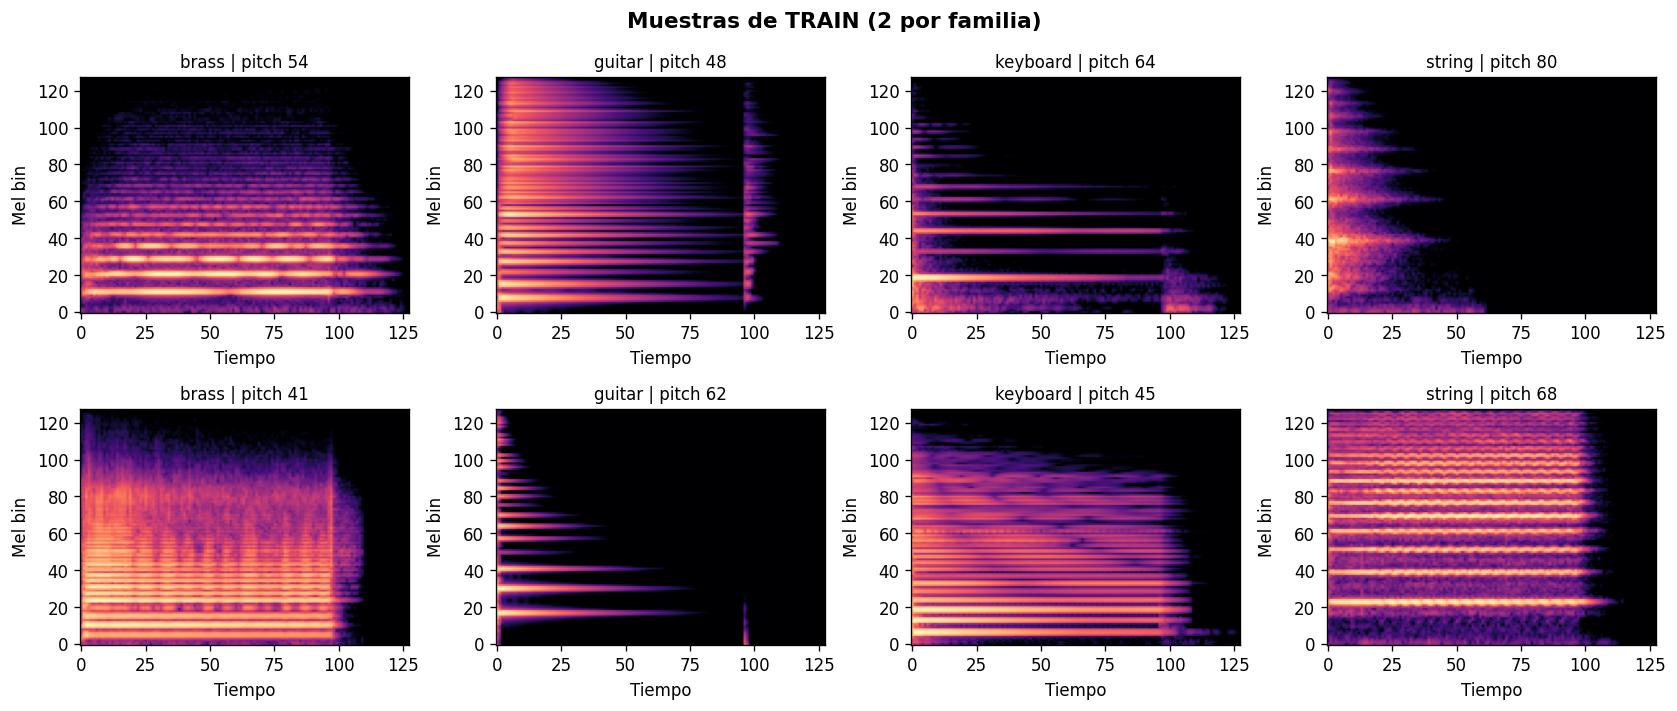

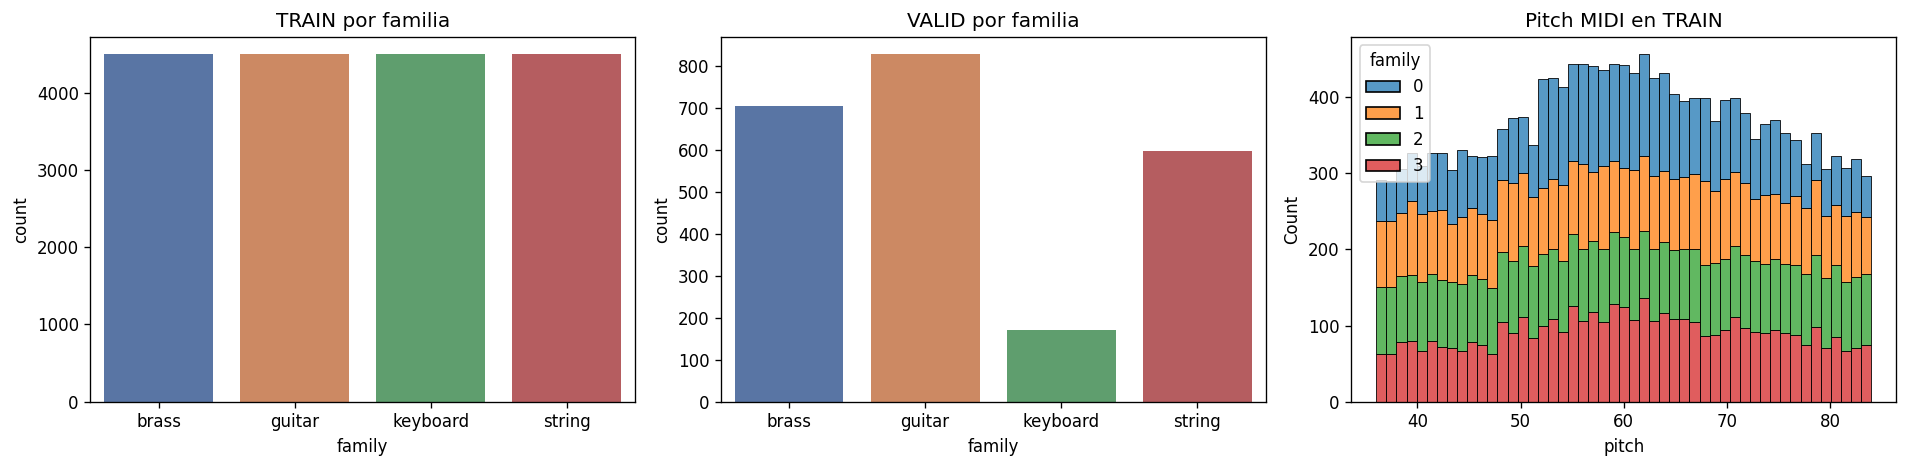

[INFO] Cobertura de pitch por familia (TRAIN):
  brass   : 49 pitches | min=36 max=84 | n=4500
  guitar  : 49 pitches | min=36 max=84 | n=4500
  keyboard: 49 pitches | min=36 max=84 | n=4500
  string  : 49 pitches | min=36 max=84 | n=4500


In [4]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6), dpi=120)
fig.suptitle('Muestras de TRAIN (2 por familia)', fontsize=13, fontweight='bold')
for col, f in enumerate(range(NUM_FAMILIES)):
    idx = (y_train == f).nonzero(as_tuple=True)[0]
    for row in range(2):
        i = idx[row].item()
        ax = axes[row, col]
        ax.imshow(X_train[i, 0].numpy(), origin='lower', aspect='auto',
                  cmap='magma', vmin=-1, vmax=1)
        ax.set_title(f'{FAMILY_NAMES[f]} | pitch {int(p_train[i])}', fontsize=10)
        ax.set_xlabel('Tiempo')
        ax.set_ylabel('Mel bin')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'muestras_train.png', dpi=120, bbox_inches='tight')
plt.show()

df_train = pd.DataFrame({'family': y_train.numpy(), 'pitch': p_train.numpy()})
df_val = pd.DataFrame({'family': y_val.numpy(), 'pitch': p_val.numpy()})

fig, axes = plt.subplots(1, 3, figsize=(16, 4), dpi=120)
sns.countplot(data=df_train, x='family', ax=axes[0], palette='deep')
axes[0].set_title('TRAIN por familia')
axes[0].set_xticklabels(FAMILY_NAMES)
sns.countplot(data=df_val, x='family', ax=axes[1], palette='deep')
axes[1].set_title('VALID por familia')
axes[1].set_xticklabels(FAMILY_NAMES)
sns.histplot(data=df_train, x='pitch', hue='family', multiple='stack',
             bins=NUM_PITCHES, ax=axes[2], palette='tab10')
axes[2].set_title('Pitch MIDI en TRAIN')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'cobertura_condiciones.png', dpi=120, bbox_inches='tight')
plt.show()

print('[INFO] Cobertura de pitch por familia (TRAIN):')
for f in range(NUM_FAMILIES):
    vals = df_train[df_train['family'] == f]['pitch']
    print(f'  {FAMILY_NAMES[f]:8s}: {vals.nunique():2d} pitches | '
          f'min={vals.min()} max={vals.max()} | n={len(vals)}')

## 5. Arquitectura del C-VAE

### ¿Qué se hace a continuación?
Se define un VAE convolucional con:
- **Encoder** de 4 bloques `Conv2d(stride=2) + BatchNorm + GELU`, de `128×128` a `8×8`.
- **Condicionamiento FiLM**: la condición `(familia, pitch)` se proyecta a un vector de 64 dimensiones y modula cada bloque con `h * (1 + γ) + β`.
- **Cuello** que concatena el vector aplanado con la condición y produce `μ` y `log σ²` de dimensión latente 128.
- **Decoder** espejo con `Upsample + Conv2d`, también condicionado por FiLM, y salida `tanh` en `[-1, 1]`.
- **Reparametrización** `z = μ + σ·ε` con `ε ~ N(0, I)`.

### ¿Por qué se hace?
FiLM es una forma barata de inyectar la condición en todas las escalas sin multiplicar parámetros. El decoder con `Upsample+Conv` evita los artefactos de tablero de `ConvTranspose2d`. La salida `tanh` respeta el rango `[-1,1]` que ya usan el juez y Griffin-Lim. Con ~10 M de parámetros el modelo entra cómodo en una T4 y entrena en minutos, no en horas.

In [5]:
class FiLM(nn.Module):
    """Modulación por escala y desplazamiento a partir de la condición."""
    def __init__(self, cond_dim, channels):
        super().__init__()
        self.to_gamma = nn.Linear(cond_dim, channels)
        self.to_beta = nn.Linear(cond_dim, channels)
        nn.init.zeros_(self.to_gamma.weight)
        nn.init.zeros_(self.to_gamma.bias)
        nn.init.zeros_(self.to_beta.weight)
        nn.init.zeros_(self.to_beta.bias)

    def forward(self, h, c):
        gamma = self.to_gamma(c)[:, :, None, None]
        beta = self.to_beta(c)[:, :, None, None]
        return h * (1.0 + gamma) + beta


class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, cond_dim):
        super().__init__()
        self.conv = nn.Conv2d(in_ch, out_ch, kernel_size=4, stride=2, padding=1)
        self.bn = nn.BatchNorm2d(out_ch)
        self.act = nn.GELU()
        self.film = FiLM(cond_dim, out_ch)

    def forward(self, x, c):
        return self.film(self.act(self.bn(self.conv(x))), c)


class UpBlock(nn.Module):
    def __init__(self, in_ch, out_ch, cond_dim):
        super().__init__()
        self.up = nn.Upsample(scale_factor=2, mode='nearest')
        self.conv = nn.Conv2d(in_ch, out_ch, kernel_size=3, stride=1, padding=1)
        self.bn = nn.BatchNorm2d(out_ch)
        self.act = nn.GELU()
        self.film = FiLM(cond_dim, out_ch)

    def forward(self, x, c):
        x = self.up(x)
        return self.film(self.act(self.bn(self.conv(x))), c)


class CondVAE(nn.Module):
    def __init__(self, latent_dim=128, base_ch=32, cond_dim=64,
                 num_families=NUM_FAMILIES, num_pitches=NUM_PITCHES):
        super().__init__()
        self.latent_dim = latent_dim
        self.cond_dim = cond_dim
        self.family_emb = nn.Embedding(num_families, 32)
        self.pitch_emb = nn.Embedding(num_pitches, 32)
        self.cond_mlp = nn.Sequential(
            nn.Linear(64, cond_dim), nn.GELU(), nn.Linear(cond_dim, cond_dim)
        )

        ch = [base_ch, base_ch * 2, base_ch * 4, base_ch * 8]
        self.enc = nn.ModuleList([
            ConvBlock(1, ch[0], cond_dim),
            ConvBlock(ch[0], ch[1], cond_dim),
            ConvBlock(ch[1], ch[2], cond_dim),
            ConvBlock(ch[2], ch[3], cond_dim),
        ])
        self.enc_out = nn.Sequential(
            nn.Conv2d(ch[3], ch[3], kernel_size=3, padding=1),
            nn.BatchNorm2d(ch[3]),
            nn.GELU(),
        )
        self.flat_dim = ch[3] * 8 * 8
        self.fc_bottleneck = nn.Sequential(
            nn.Linear(self.flat_dim + cond_dim, 256), nn.GELU()
        )
        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)
        self.fc_decode = nn.Sequential(
            nn.Linear(latent_dim + cond_dim, 256),
            nn.GELU(),
            nn.Linear(256, self.flat_dim),
            nn.GELU(),
        )
        self.dec = nn.ModuleList([
            UpBlock(ch[3], ch[2], cond_dim),
            UpBlock(ch[2], ch[1], cond_dim),
            UpBlock(ch[1], ch[0], cond_dim),
            UpBlock(ch[0], max(base_ch // 2, 8), cond_dim),
        ])
        self.final = nn.Conv2d(max(base_ch // 2, 8), 1, kernel_size=3, padding=1)

    def condition(self, family, pitch):
        p = (pitch - PITCH_MIN).clamp(0, NUM_PITCHES - 1)
        c = torch.cat([self.family_emb(family), self.pitch_emb(p)], dim=1)
        return self.cond_mlp(c)

    def encode(self, x, family, pitch):
        c = self.condition(family, pitch)
        h = x
        for block in self.enc:
            h = block(h, c)
        h = self.enc_out(h)
        h = h.flatten(1)
        h = self.fc_bottleneck(torch.cat([h, c], dim=1))
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z, family, pitch):
        c = self.condition(family, pitch)
        h = self.fc_decode(torch.cat([z, c], dim=1))
        h = h.view(-1, self.dec[0].conv.in_channels, 8, 8)
        for block in self.dec:
            h = block(h, c)
        return torch.tanh(self.final(h))

    def forward(self, x, family, pitch):
        mu, logvar = self.encode(x, family, pitch)
        z = self.reparameterize(mu, logvar)
        return self.decode(z, family, pitch), mu, logvar


model_test = CondVAE(latent_dim=128, base_ch=32, cond_dim=64).to(device)
n_params = sum(p.numel() for p in model_test.parameters() if p.requires_grad)
print(f'[INFO] CondVAE — parámetros entrenables: {n_params:,} ({n_params/1e6:.2f} M)')

with torch.no_grad():
    dummy = torch.zeros(2, 1, IMG_SIZE, IMG_SIZE, device=device)
    fam_d = torch.tensor([0, 1], device=device)
    pit_d = torch.tensor([60, 72], device=device)
    out, mu_d, lv_d = model_test(dummy, fam_d, pit_d)
print(f'[INFO] Salida: {tuple(out.shape)} | mu: {tuple(mu_d.shape)} | logvar: {tuple(lv_d.shape)}')
del model_test, dummy, out, mu_d, lv_d
torch.cuda.empty_cache()

[INFO] CondVAE — parámetros entrenables: 10,313,665 (10.31 M)
[INFO] Salida: (2, 1, 128, 128) | mu: (2, 128) | logvar: (2, 128)


## 6. Pérdida, vocoder Griffin-Lim y utilidades de entrenamiento

### ¿Qué se hace a continuación?
Se definen:
- la pérdida `L1 + β·KL` con `β` que sube linealmente durante los primeros 5 epochs y después se ajusta automáticamente para mantener el KL cerca de **200 nats**;
- el vocoder Griffin-Lim que revierte `(dB+40)/40`, sintetiza con la escala mel correcta y limpia el audio con compuerta suave, fade y normalización única;
- las funciones de guardado atómico y carga de checkpoints;
- los hiperparámetros del entrenamiento.

### ¿Por qué se hace?
La L1 produce espectrogramas más nítidos que la MSE, que tiende a promediar y borronear los armónicos. El warmup de `β` evita que el término KL colapse el latente en las primeras épocas, cuando la reconstrucción todavía es mala.

Después del warmup, `β` se corrige con un controlador proporcional en escala logarítmica. La razón es concreta: con `β` fijo y chico, el KL crece sin límite (en una prueba corta pasó de 1 a 145 en dos epochs) y el posterior agregado se aleja de `N(0, I)`. Cuando eso pasa, `z ~ N(0, I)` cae fuera de la región que el decoder vio entrenar y las muestras del prior salen borrosas o sin sentido. Mantener el KL en ~200 nats para 128 dimensiones (≈1.6 nats por dimensión) deja el posterior cerca del prior sin resignar toda la reconstrucción.

El guardado atómico evita checkpoints corruptos si Kaggle corta la sesión justo mientras escribe. Griffin-Lim es el mismo vocoder del control inicial: así los audios generados son comparables con los reales.

El vocoder invierte exactamente `(dB + 40) / 40`. La escala mel tiene que ser la del análisis (`htk=True, norm=None`, el default de `torchaudio.MelSpectrogram`): si no coincide, el filtro de inversión queda mal y el timbre se arruina. La compuerta suave (−40 dB respecto del pico, rodilla de 8 dB y 30 ms de suavizado) apaga el hiss que Griffin-Lim deja en los silencios sin tocar el cuerpo de la nota; el fade de 15 ms evita clicks y la normalización se aplica una sola vez, al final. Antes había un pre-énfasis y una doble normalización que dejaban los WAV casi inaudibles y con ruido de cuantización al subirles el volumen.

In [6]:
# ── Hiperparámetros ─────────────────────────────────────────────────────────
LATENT_DIM = 128
BASE_CH = 32
COND_DIM = 64
LR = 5e-4
WEIGHT_DECAY = 1e-4
EPOCHS = 80
WARMUP_EPOCHS = 3
PATIENCE = 15
BETA_KL = 1e-3
KL_TARGET = 200.0
BETA_MIN, BETA_MAX = 1e-4, 3e-2
KL_WARMUP_EPOCHS = 5
MAX_TRAIN_MINUTES = 40
RESUME = True

# ── Audio ───────────────────────────────────────────────────────────────────
# El análisis (NB01) usó torchaudio.MelSpectrogram con n_fft=1024, escala HTK y
# norm=None, con normalización por pico. Para sintetizar usamos n_fft=2048:
# Griffin-Lim necesita más solapamiento (75 % con hop=500 en vez de 50 %).
# La escala mel (HTK, norm=None) sí tiene que coincidir con el análisis.
SR = 16000
N_FFT = 2048
HOP = 500
N_MELS = 128
GATE_DB = -40.0
FADE_MS = 15

# ── Pérdida ─────────────────────────────────────────────────────────────────
def vae_loss(recon, x, mu, logvar, beta):
    recon_loss = F.l1_loss(recon, x)
    mu = mu.float()
    logvar = logvar.float()
    kl_per_dim = -0.5 * (1.0 + logvar - mu.pow(2) - logvar.exp())
    kl = kl_per_dim.sum(dim=1).mean()
    return recon_loss + beta * kl, recon_loss, kl, kl_per_dim.mean(dim=0)


def beta_en_epoch(epoch, beta_actual=BETA_KL, kl_prev=None):
    """Warmup lineal y luego control proporcional del KL (en escala log)."""
    if epoch < KL_WARMUP_EPOCHS:
        return BETA_KL * (epoch + 1) / KL_WARMUP_EPOCHS
    if kl_prev is None or not np.isfinite(kl_prev):
        return beta_actual
    factor = math.exp(0.7 * (kl_prev / KL_TARGET - 1.0))
    return float(np.clip(beta_actual * factor, BETA_MIN, BETA_MAX))


# ── Checkpoints ─────────────────────────────────────────────────────────────
def guardar_checkpoint(path, payload):
    tmp = path.with_suffix(path.suffix + '.tmp')
    torch.save(payload, tmp)
    os.replace(tmp, path)


def cargar_checkpoint(path, device):
    try:
        return torch.load(path, map_location=device, weights_only=False)
    except TypeError:
        return torch.load(path, map_location=device)


# ── Vocoder Griffin-Lim ─────────────────────────────────────────────────────
class GriffinLimVocoder:
    """Invierte mel [-1, 1] a audio.

    Coincide con el preprocesado: escala mel HTK, norm=None y dB = 40*v - 40.
    Limpia el resultado con compuerta suave (hiss de Griffin-Lim en silencios),
    fade de 15 ms y una única normalización de pico.
    """

    def __init__(self, sample_rate=SR, n_fft=N_FFT, hop_length=HOP, n_mels=N_MELS):
        self.sample_rate = sample_rate
        self.n_fft = n_fft
        self.hop_length = hop_length
        self.n_mels = n_mels

    @staticmethod
    def _compuerta_suave(wav, sr, umbral_db=-40.0, rodilla_db=8.0, suav_ms=30):
        """Atenúa lo que está por debajo del umbral (relativo al pico)."""
        win = max(1, int(sr * 0.02))  # 20 ms
        if len(wav) < win:
            return wav
        env = np.sqrt(np.convolve(wav ** 2, np.ones(win) / win, mode='same'))
        ref = max(float(env.max()), 1e-12)
        db = 20.0 * np.log10(env / ref + 1e-12)
        gan = np.clip((db - (umbral_db - rodilla_db)) / rodilla_db, 0.0, 1.0)
        k = max(1, int(sr * suav_ms / 1000))
        gan = np.convolve(gan, np.ones(k) / k, mode='same')
        return (wav * gan).astype(np.float32)

    def mel_norm_to_audio(self, mel_norm, n_iter=250, gate_db=GATE_DB, fade_ms=FADE_MS):
        mel = np.asarray(mel_norm, dtype=np.float32)
        mel_power = librosa.db_to_power(mel * 40.0 - 40.0, ref=1.0)
        wav = librosa.feature.inverse.mel_to_audio(
            mel_power,
            sr=self.sample_rate,
            n_fft=self.n_fft,
            win_length=self.n_fft,
            hop_length=self.hop_length,
            power=2.0,
            n_iter=n_iter,
            htk=True,
            norm=None,
        )
        wav = np.asarray(wav, dtype=np.float32)
        if wav.size == 0:
            return wav

        # Griffin-Lim con center=True devuelve (n_frames - 1) * hop muestras;
        # lo llevamos exactamente a 128 * hop = 64.000 muestras (4 s a 16 kHz).
        objetivo = int(mel.shape[1] * self.hop_length)
        if wav.size < objetivo:
            wav = np.pad(wav, (0, objetivo - wav.size))
        else:
            wav = wav[:objetivo]

        wav = wav - float(wav.mean())                      # quita offset DC
        if gate_db is not None:
            wav = self._compuerta_suave(wav, self.sample_rate, umbral_db=gate_db)

        nf = int(self.sample_rate * fade_ms / 1000)        # fade in/out
        if nf > 0 and len(wav) > 2 * nf:
            wav[:nf] *= np.linspace(0.0, 1.0, nf, dtype=np.float32)
            wav[-nf:] *= np.linspace(1.0, 0.0, nf, dtype=np.float32)

        pico = float(np.max(np.abs(wav)))                  # normalización única
        if pico > 1e-7:
            wav = wav / pico * 0.95
        return wav.astype(np.float32)


def to_py(obj):
    """Convierte tipos numpy/torch a tipos serializables en JSON."""
    if isinstance(obj, dict):
        return {str(k): to_py(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [to_py(v) for v in obj]
    if isinstance(obj, (np.floating, np.integer)):
        return obj.item()
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, torch.Tensor):
        return obj.detach().cpu().tolist()
    return obj


vocoder = GriffinLimVocoder()
print('[INFO] Vocoder Griffin-Lim listo.')
print(f'[INFO] n_fft={N_FFT} | hop={HOP} | mel HTK norm=None | '
      f'gate={GATE_DB} dB | fade={FADE_MS} ms | normalización única a 0.95')
print(f'[INFO] Config: latent={LATENT_DIM} | base_ch={BASE_CH} | batch={BATCH_SIZE} | '
      f'lr={LR} | epochs={EPOCHS} | beta0={BETA_KL} | kl_target={KL_TARGET} | '
      f'time_budget={MAX_TRAIN_MINUTES} min')

[INFO] Vocoder Griffin-Lim listo.
[INFO] n_fft=2048 | hop=500 | mel HTK norm=None | gate=-40.0 dB | fade=15 ms | normalización única a 0.95
[INFO] Config: latent=128 | base_ch=32 | batch=64 | lr=0.0005 | epochs=80 | beta0=0.001 | kl_target=200.0 | time_budget=40 min


## 7. Smoke test antes de entrenar

### ¿Qué se hace a continuación?
Se crea un modelo temporal, se procesa **un solo batch** con forward, pérdida, backward y un paso de optimizador, se generan 4 muestras desde el prior y se pasa una de ellas por Griffin-Lim.

### ¿Por qué se hace?
Es el seguro contra el escenario que querés evitar: entrenar 40 minutos y que recién ahí aparezca una excepción. Acá se verifican shapes, pérdida finita, gradientes, decodificación, rango de salida y que el vocoder produzca audio no silencioso. Cuesta menos de un minuto y descarta los errores más caros.

In [7]:
torch.manual_seed(SEED)
model_test = CondVAE(latent_dim=LATENT_DIM, base_ch=BASE_CH, cond_dim=COND_DIM).to(device)
opt_test = torch.optim.AdamW(model_test.parameters(), lr=1e-4)
scaler_test = torch.cuda.amp.GradScaler(enabled=use_amp)

xb, fb, pb = next(iter(loader_train))
xb = xb.to(device)
fb = fb.to(device)
pb = pb.to(device)

model_test.train()
opt_test.zero_grad(set_to_none=True)
with torch.cuda.amp.autocast(enabled=use_amp):
    recon, mu, logvar = model_test(xb, fb, pb)
    loss, rl, kl, _ = vae_loss(recon, xb, mu.float(), logvar.float(), BETA_KL)

print(f'[INFO] recon={tuple(recon.shape)} | mu={tuple(mu.shape)} | logvar={tuple(logvar.shape)}')
print(f'[INFO] loss={loss.item():.5f} | recon={rl.item():.5f} | kl={kl.item():.3f}')
assert torch.isfinite(loss).item(), 'La pérdida no es finita'

scaler_test.scale(loss).backward()
scaler_test.unscale_(opt_test)
torch.nn.utils.clip_grad_norm_(model_test.parameters(), 1.0)
scaler_test.step(opt_test)
scaler_test.update()
print('[OK] Forward, backward y optimizer step funcionan.')

model_test.eval()
with torch.no_grad():
    z = torch.randn(4, LATENT_DIM, device=device)
    fam_s = torch.tensor([0, 1, 2, 3], device=device)
    pit_s = torch.tensor([60, 60, 60, 60], device=device)
    with torch.cuda.amp.autocast(enabled=use_amp):
        muestras = model_test.decode(z, fam_s, pit_s)

print(f'[INFO] Muestras: {tuple(muestras.shape)} | '
      f'rango=[{muestras.min():.3f}, {muestras.max():.3f}] | '
      f'finite={torch.isfinite(muestras).all().item()}')
assert torch.isfinite(muestras).all().item(), 'Las muestras contienen NaN/Inf'

wav_test = vocoder.mel_norm_to_audio(muestras[0, 0].cpu().numpy(), n_iter=32)
print(f'[INFO] Audio de prueba: {wav_test.shape} | max|y|={np.abs(wav_test).max():.4f}')
assert np.abs(wav_test).max() > 1e-3, 'Griffin-Lim devolvió audio silencioso'

del model_test, opt_test, scaler_test, xb, fb, pb, recon, mu, logvar, muestras
torch.cuda.empty_cache()
print('[OK] Smoke test completo. Podés entrenar con tranquilidad.')

[INFO] recon=(64, 1, 128, 128) | mu=(64, 128) | logvar=(64, 128)
[INFO] loss=0.87451 | recon=0.87294 | kl=1.571
[OK] Forward, backward y optimizer step funcionan.
[INFO] Muestras: (4, 1, 128, 128) | rango=[-0.008, 0.013] | finite=True
[INFO] Audio de prueba: (64000,) | max|y|=0.9500
[OK] Smoke test completo. Podés entrenar con tranquilidad.


## 8. Piloto de 3 epochs

### ¿Qué se hace a continuación?
Se entrena un modelo temporal durante 3 epochs con 2.000 muestras estratificadas (500 por familia). No se guarda: es solo una prueba de convergencia.

### ¿Por qué se hace?
El smoke test valida que el código no explota; el piloto valida que el modelo **aprende**. Si la pérdida baja en 3 epochs con 2.000 muestras, hay buenas chances de que las 80 epochs completas converjan. Si no baja, conviene ajustar `LR` o `β` antes de gastar 40 minutos.

In [8]:
RUN_PILOT = True

if RUN_PILOT:
    torch.manual_seed(SEED)
    idx_pilot = []
    for f in range(NUM_FAMILIES):
        idx_f = (y_train == f).nonzero(as_tuple=True)[0]
        perm = torch.randperm(len(idx_f))[:500]
        idx_pilot.append(idx_f[perm])
    idx_pilot = torch.cat(idx_pilot)

    ds_pilot = TensorDataset(X_train[idx_pilot], y_train[idx_pilot], p_train[idx_pilot])
    loader_pilot = DataLoader(ds_pilot, batch_size=BATCH_SIZE, shuffle=True,
                              drop_last=True, num_workers=0, pin_memory=use_amp)

    model_pilot = CondVAE(latent_dim=LATENT_DIM, base_ch=BASE_CH, cond_dim=COND_DIM).to(device)
    opt_pilot = torch.optim.AdamW(model_pilot.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scaler_pilot = torch.cuda.amp.GradScaler(enabled=use_amp)

    print(f'[INFO] Piloto: {len(ds_pilot)} muestras | {len(loader_pilot)} batches')
    for ep in range(3):
        model_pilot.train()
        acum, n = 0.0, 0
        for xb, fb, pb in tqdm(loader_pilot, desc=f'Piloto {ep+1}/3', leave=False):
            xb = xb.to(device, non_blocking=True)
            fb = fb.to(device, non_blocking=True)
            pb = pb.to(device, non_blocking=True)
            opt_pilot.zero_grad(set_to_none=True)
            with torch.cuda.amp.autocast(enabled=use_amp):
                recon, mu, logvar = model_pilot(xb, fb, pb)
                loss, rl, kl, _ = vae_loss(recon, xb, mu.float(), logvar.float(), beta_en_epoch(ep))
            if not torch.isfinite(loss):
                continue
            scaler_pilot.scale(loss).backward()
            scaler_pilot.unscale_(opt_pilot)
            torch.nn.utils.clip_grad_norm_(model_pilot.parameters(), 1.0)
            scaler_pilot.step(opt_pilot)
            scaler_pilot.update()
            acum += loss.item()
            n += 1
        print(f'[INFO] Piloto epoch {ep+1}: loss={acum/max(n,1):.4f} | batches={n}')

    del model_pilot, opt_pilot, scaler_pilot
    torch.cuda.empty_cache()
    print('[OK] Piloto finalizado. Si la loss bajó, seguí con el entrenamiento completo.')
else:
    print('[INFO] Piloto desactivado (RUN_PILOT=False).')

[INFO] Piloto: 2000 muestras | 31 batches


Piloto 1/3:   0%|          | 0/31 [00:00<?, ?it/s]

[INFO] Piloto epoch 1: loss=0.4119 | batches=31


Piloto 2/3:   0%|          | 0/31 [00:00<?, ?it/s]

[INFO] Piloto epoch 2: loss=0.1743 | batches=31


Piloto 3/3:   0%|          | 0/31 [00:00<?, ?it/s]

[INFO] Piloto epoch 3: loss=0.1658 | batches=31
[OK] Piloto finalizado. Si la loss bajó, seguí con el entrenamiento completo.


## 9. Entrenamiento completo del C-VAE

### ¿Qué se hace a continuación?
Se entrena el modelo definitivo con AdamW, AMP, warmup + cosine, clipping de gradientes, early stopping y un presupuesto máximo de 40 minutos. En cada epoch, después del warmup, `β` se reajusta según el KL observado en `valid` para acercarlo al objetivo de 200 nats. Se guarda:
- `vae_last.pt` al final de **cada** epoch, para poder reanudar;
- `vae_best.pt` cuando mejora la reconstrucción en `valid`;
- `historial.csv` con todas las métricas;
- `vae_crash.pt` si ocurre una excepción.

### ¿Por qué se hace?
El early stopping evita sobreajuste y el presupuesto de tiempo evita quedarse sin cuota. Guardar cada epoch y poder reanudar convierte una posible pérdida de 40 minutos en una pérdida de, como mucho, una epoch. La selección del mejor modelo se hace por **reconstrucción en validación** (L1), que es más estable que el ELBO total para decidir cuándo el decoder dejó de mejorar. Por eso la curva de `val_loss` puede subir o bajar con los cambios de `β`: la decisión de cuál checkpoint usar no depende de ella.

Al final se mide el KL del mejor modelo en `valid`. Si quedó muy por encima del objetivo, el notebook avisa: significa que el posterior agregado se alejó del prior y que conviene revisar las muestras del prior antes de usarlas en el torneo.

In [9]:
model = CondVAE(latent_dim=LATENT_DIM, base_ch=BASE_CH, cond_dim=COND_DIM).to(device)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'[INFO] CVAE — parámetros entrenables: {n_params:,} ({n_params/1e6:.2f} M)')

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
warmup_sched = torch.optim.lr_scheduler.LinearLR(
    optimizer, start_factor=0.1, end_factor=1.0, total_iters=max(1, WARMUP_EPOCHS)
)
cosine_sched = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=max(1, EPOCHS - WARMUP_EPOCHS), eta_min=1e-6
)
scheduler = torch.optim.lr_scheduler.SequentialLR(
    optimizer, schedulers=[warmup_sched, cosine_sched], milestones=[max(1, WARMUP_EPOCHS)]
)
scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

config_actual = {
    'latent_dim': LATENT_DIM,
    'base_ch': BASE_CH,
    'cond_dim': COND_DIM,
    'batch_size': BATCH_SIZE,
    'lr': LR,
    'weight_decay': WEIGHT_DECAY,
    'beta_kl': BETA_KL,
    'kl_target': KL_TARGET,
    'kl_warmup_epochs': KL_WARMUP_EPOCHS,
    'epochs': EPOCHS,
    'seed': SEED,
}

ckpt_last = OUTPUT_DIR / 'vae_last.pt'
ckpt_best = OUTPUT_DIR / 'vae_best.pt'
historial = {
    'epoch': [], 'train_loss': [], 'train_recon': [], 'train_kl': [],
    'val_loss': [], 'val_recon': [], 'val_kl': [],
    'beta': [], 'lr': [], 'active_units': [], 'epoch_time_s': [],
}
start_epoch = 0
best_val_recon = float('inf')
paciencia = 0
beta_actual = BETA_KL
val_kl_prev = None

if RESUME and ckpt_last.exists():
    ck = cargar_checkpoint(ckpt_last, device)
    cfg = ck.get('config', {})
    compatible = (
        cfg.get('latent_dim') == LATENT_DIM and
        cfg.get('base_ch') == BASE_CH and
        cfg.get('cond_dim') == COND_DIM and
        cfg.get('batch_size') == BATCH_SIZE
    )
    if compatible:
        model.load_state_dict(ck['model'])
        optimizer.load_state_dict(ck['optimizer'])
        scheduler.load_state_dict(ck['scheduler'])
        scaler.load_state_dict(ck['scaler'])
        start_epoch = ck['epoch'] + 1
        historial = ck['historial']
        best_val_recon = ck.get('best_val_recon', float('inf'))
        paciencia = ck.get('paciencia', 0)
        beta_actual = ck.get('beta_actual', BETA_KL)
        val_kl_prev = ck.get('val_kl_prev', None)
        print(f'[INFO] Reanudando desde epoch {start_epoch} | best_val_recon={best_val_recon:.5f} | '
              f'beta={beta_actual:.1e}')
    else:
        print('[ADVERTENCIA] Checkpoint incompatible con la config actual. Se empieza de cero.')

t_inicio = time.time()
try:
    for epoch in range(start_epoch, EPOCHS):
        t_ep = time.time()
        beta = beta_en_epoch(epoch, beta_actual, val_kl_prev)

        # ── Train ────────────────────────────────────────────────────────
        model.train()
        tr_loss = tr_recon = tr_kl = 0.0
        n_batches = 0
        pbar = tqdm(loader_train, desc=f'Ep {epoch+1}/{EPOCHS}', leave=False)
        for xb, fb, pb in pbar:
            xb = xb.to(device, non_blocking=True)
            fb = fb.to(device, non_blocking=True)
            pb = pb.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            with torch.cuda.amp.autocast(enabled=use_amp):
                recon, mu, logvar = model(xb, fb, pb)
                loss, rl, kl, _ = vae_loss(recon, xb, mu.float(), logvar.float(), beta)

            if not torch.isfinite(loss):
                print('[ADVERTENCIA] Loss no finita; se saltea el batch.')
                continue

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()

            tr_loss += loss.item()
            tr_recon += rl.item()
            tr_kl += kl.item()
            n_batches += 1
            pbar.set_postfix(loss=f'{loss.item():.4f}', kl=f'{kl.item():.1f}')

        if n_batches == 0:
            raise RuntimeError('No se procesó ningún batch finito en esta época.')

        scheduler.step()

        # ── Validación ───────────────────────────────────────────────────
        model.eval()
        va_loss = va_recon = va_kl = 0.0
        n_val = 0
        kl_dim_sum = torch.zeros(LATENT_DIM, device=device)
        with torch.no_grad():
            for xb, fb, pb in loader_val:
                xb = xb.to(device, non_blocking=True)
                fb = fb.to(device, non_blocking=True)
                pb = pb.to(device, non_blocking=True)
                with torch.cuda.amp.autocast(enabled=use_amp):
                    recon, mu, logvar = model(xb, fb, pb)
                    loss, rl, kl, kl_dim = vae_loss(recon, xb, mu.float(), logvar.float(), beta)
                va_loss += loss.item() * len(xb)
                va_recon += rl.item() * len(xb)
                va_kl += kl.item() * len(xb)
                kl_dim_sum += kl_dim.float() * len(xb)
                n_val += len(xb)

        va_loss /= n_val
        va_recon /= n_val
        va_kl /= n_val
        kl_dim_mean = kl_dim_sum / n_val
        active_units = int((kl_dim_mean > 0.1).sum().item())
        beta_actual = beta
        val_kl_prev = va_kl

        # ── Historial ────────────────────────────────────────────────────
        historial['epoch'].append(epoch + 1)
        historial['train_loss'].append(tr_loss / n_batches)
        historial['train_recon'].append(tr_recon / n_batches)
        historial['train_kl'].append(tr_kl / n_batches)
        historial['val_loss'].append(va_loss)
        historial['val_recon'].append(va_recon)
        historial['val_kl'].append(va_kl)
        historial['beta'].append(beta)
        historial['lr'].append(optimizer.param_groups[0]['lr'])
        historial['active_units'].append(active_units)
        historial['epoch_time_s'].append(time.time() - t_ep)

        # ── Checkpoints ──────────────────────────────────────────────────
        payload = {
            'config': config_actual,
            'epoch': epoch,
            'model': model.state_dict(),
            'optimizer': optimizer.state_dict(),
            'scheduler': scheduler.state_dict(),
            'scaler': scaler.state_dict(),
            'historial': historial,
            'best_val_recon': best_val_recon,
            'paciencia': paciencia,
            'beta_actual': beta_actual,
            'val_kl_prev': val_kl_prev,
        }

        if va_recon < best_val_recon:
            best_val_recon = va_recon
            paciencia = 0
            payload['best_val_recon'] = best_val_recon
            payload['paciencia'] = paciencia
            guardar_checkpoint(ckpt_best, payload)
        else:
            paciencia += 1
            payload['paciencia'] = paciencia

        guardar_checkpoint(ckpt_last, payload)
        pd.DataFrame(historial).to_csv(OUTPUT_DIR / 'historial.csv', index=False)

        print(f'[EPOCH {epoch+1}/{EPOCHS}] '
              f'train_loss={tr_loss/n_batches:.4f} | train_recon={tr_recon/n_batches:.4f} | '
              f'train_kl={tr_kl/n_batches:.2f} | val_loss={va_loss:.4f} | '
              f'val_recon={va_recon:.4f} | val_kl={va_kl:.2f} | '
              f'active={active_units}/{LATENT_DIM} | beta={beta:.1e} | '
              f'{historial["epoch_time_s"][-1]/60:.1f} min')

        if paciencia >= PATIENCE:
            print(f'[INFO] Early stopping en epoch {epoch+1}.')
            break

        elapsed_min = (time.time() - t_inicio) / 60
        if elapsed_min >= MAX_TRAIN_MINUTES:
            print(f'[INFO] Presupuesto de tiempo alcanzado ({elapsed_min:.1f} min). '
                  f'Se detiene y se guarda el estado.')
            break

except Exception:
    print('[ERROR] Excepción durante el entrenamiento. Se guarda el estado de emergencia.')
    payload = {
        'config': config_actual,
        'epoch': epoch if 'epoch' in locals() else 0,
        'model': model.state_dict(),
        'optimizer': optimizer.state_dict(),
        'scheduler': scheduler.state_dict(),
        'scaler': scaler.state_dict(),
        'historial': historial,
        'best_val_recon': best_val_recon,
        'paciencia': paciencia,
        'beta_actual': beta_actual,
        'val_kl_prev': val_kl_prev,
    }
    guardar_checkpoint(OUTPUT_DIR / 'vae_crash.pt', payload)
    traceback.print_exc()
    raise

# ── Cargar el mejor checkpoint ──────────────────────────────────────────────
if ckpt_best.exists():
    ck = cargar_checkpoint(ckpt_best, device)
    model.load_state_dict(ck['model'])
    print(f'[INFO] Mejor checkpoint cargado: epoch {ck["epoch"]+1} | '
          f'val_recon={ck.get("best_val_recon", float("inf")):.5f}')
model.eval()

# ── Diagnóstico del KL del mejor modelo ────────────────────────────────────
kl_best, n_kl = 0.0, 0
with torch.no_grad():
    for xb, fb, pb in loader_val:
        xb = xb.to(device, non_blocking=True)
        fb = fb.to(device, non_blocking=True)
        pb = pb.to(device, non_blocking=True)
        mu, logvar = model.encode(xb, fb, pb)
        mu, logvar = mu.float(), logvar.float()
        kl_b = -0.5 * (1.0 + logvar - mu.pow(2) - logvar.exp()).sum(dim=1)
        kl_best += kl_b.sum().item()
        n_kl += len(xb)
kl_best /= max(n_kl, 1)
print(f'[INFO] KL del mejor modelo en valid: {kl_best:.1f} nats '
      f'({kl_best/LATENT_DIM:.2f} por dimensión) | objetivo={KL_TARGET:.0f}')
if kl_best > 3 * KL_TARGET:
    print('[ADVERTENCIA] El KL superó 3x el objetivo: el posterior agregado puede estar lejos '
          'de N(0,I). Revisá muestras_generadas.png y, si hace falta, subí KL_TARGET o bajá BETA_MIN.')

historial_df = pd.DataFrame(historial)
historial_df.to_csv(OUTPUT_DIR / 'historial.csv', index=False)
print(f'[INFO] Épocas registradas: {len(historial_df)}')

[INFO] CVAE — parámetros entrenables: 10,313,665 (10.31 M)
[INFO] Reanudando desde epoch 80 | best_val_recon=0.05778 | beta=1.0e-04
[INFO] Mejor checkpoint cargado: epoch 75 | val_recon=0.05778
[INFO] KL del mejor modelo en valid: 34.8 nats (0.27 por dimensión) | objetivo=200
[INFO] Épocas registradas: 80


## 10. Curvas de aprendizaje

### ¿Qué se hace a continuación?
Se grafican la pérdida total, la reconstrucción, el KL, las unidades activas del latente, el learning rate y el tiempo por epoch.

### ¿Por qué se hace?
Las curvas permiten diagnosticar tres cosas: si el modelo sigue mejorando, si el KL se está usando (unidades activas > 0) y si el costo por epoch es razonable. Un KL pegado a cero indica colapso del posterior; una reconstrucción que sube en validación indica sobreajuste.

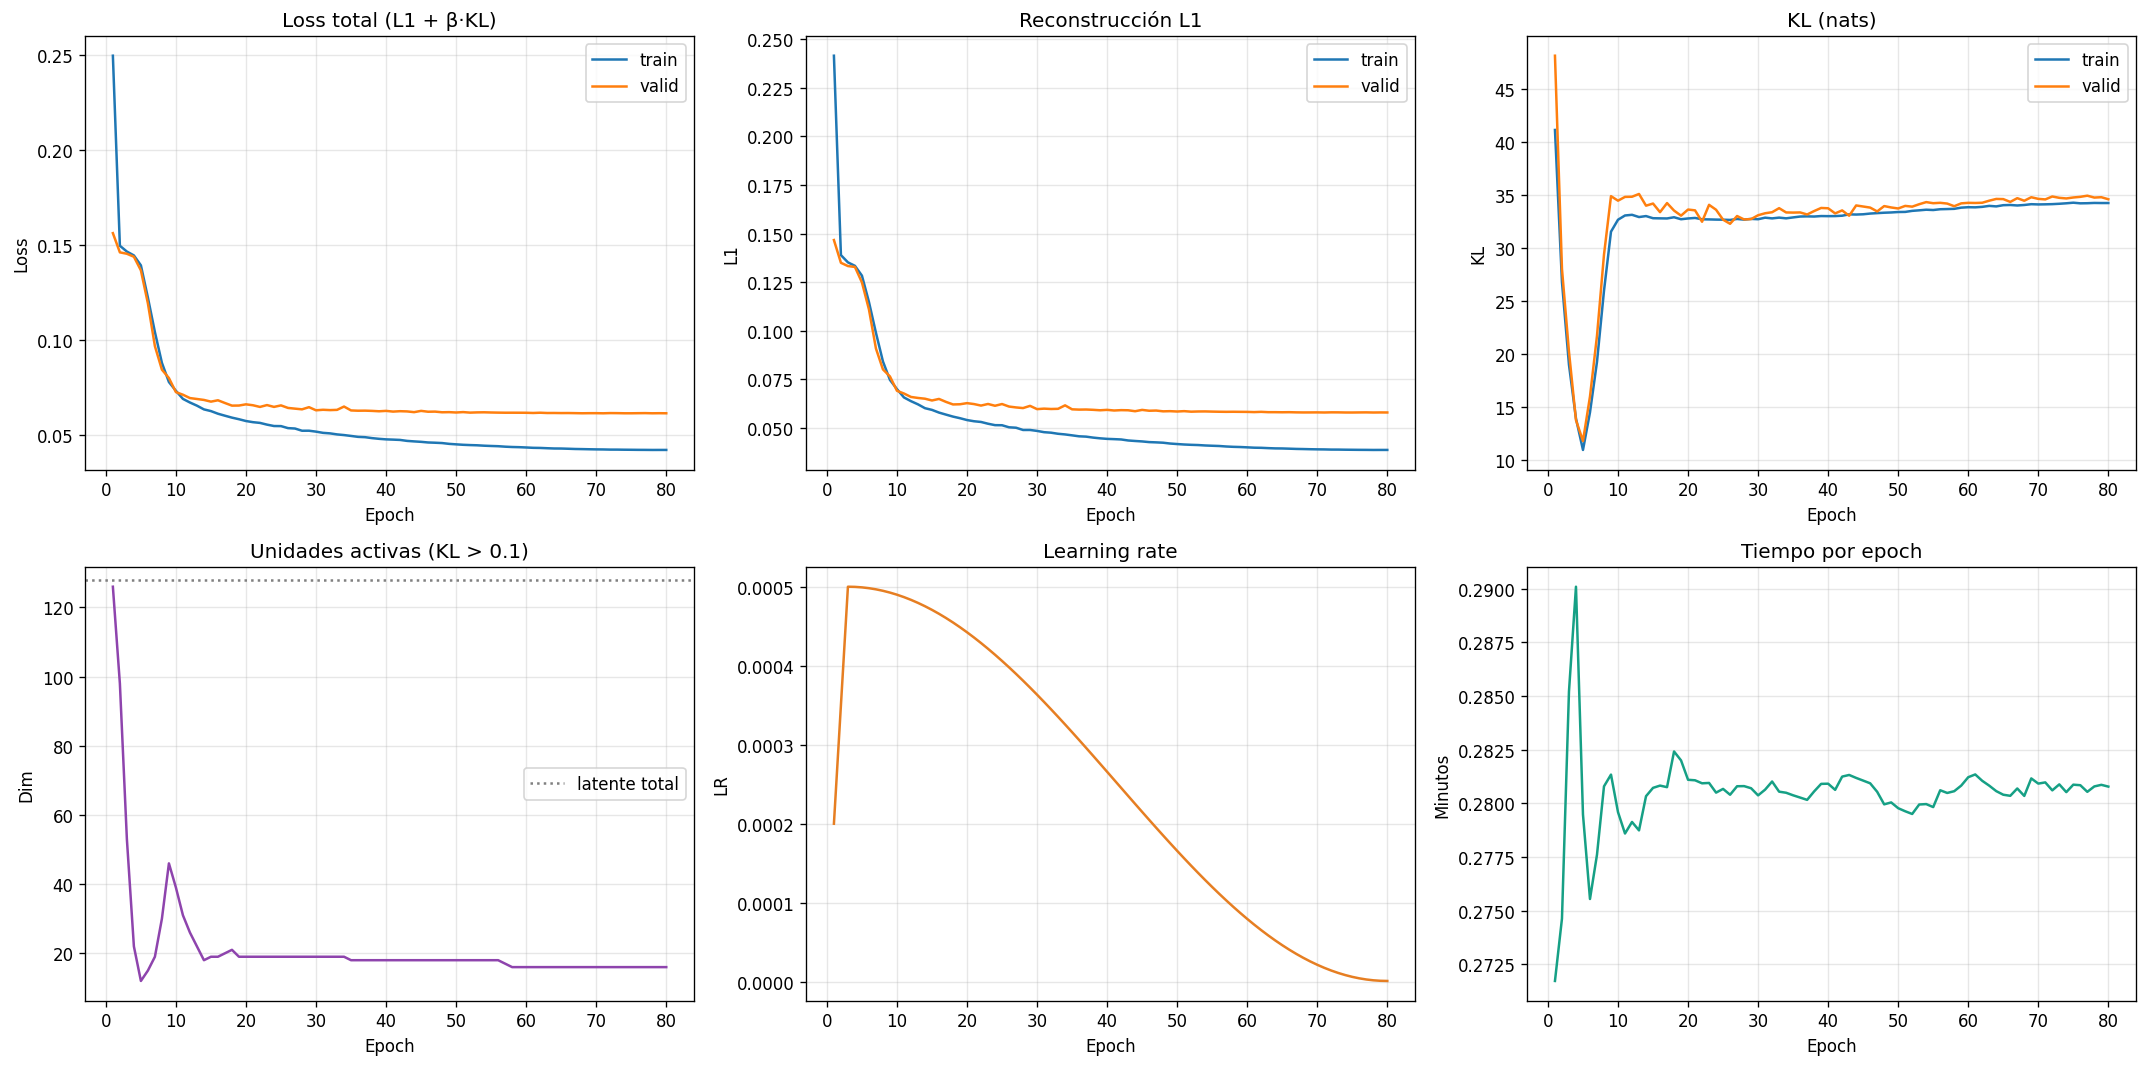

In [10]:
if len(historial_df) > 0:
    fig, axes = plt.subplots(2, 3, figsize=(18, 9), dpi=120)

    ax = axes[0, 0]
    ax.plot(historial_df['epoch'], historial_df['train_loss'], label='train')
    ax.plot(historial_df['epoch'], historial_df['val_loss'], label='valid')
    ax.set_title('Loss total (L1 + β·KL)')
    ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
    ax.legend(); ax.grid(alpha=0.3)

    ax = axes[0, 1]
    ax.plot(historial_df['epoch'], historial_df['train_recon'], label='train')
    ax.plot(historial_df['epoch'], historial_df['val_recon'], label='valid')
    ax.set_title('Reconstrucción L1')
    ax.set_xlabel('Epoch'); ax.set_ylabel('L1')
    ax.legend(); ax.grid(alpha=0.3)

    ax = axes[0, 2]
    ax.plot(historial_df['epoch'], historial_df['train_kl'], label='train')
    ax.plot(historial_df['epoch'], historial_df['val_kl'], label='valid')
    ax.set_title('KL (nats)')
    ax.set_xlabel('Epoch'); ax.set_ylabel('KL')
    ax.legend(); ax.grid(alpha=0.3)

    ax = axes[1, 0]
    ax.plot(historial_df['epoch'], historial_df['active_units'], color='#8e44ad')
    ax.axhline(LATENT_DIM, color='gray', linestyle=':', label='latente total')
    ax.set_title('Unidades activas (KL > 0.1)')
    ax.set_xlabel('Epoch'); ax.set_ylabel('Dim')
    ax.legend(); ax.grid(alpha=0.3)

    ax = axes[1, 1]
    ax.plot(historial_df['epoch'], historial_df['lr'], color='#e67e22')
    ax.set_title('Learning rate')
    ax.set_xlabel('Epoch'); ax.set_ylabel('LR')
    ax.grid(alpha=0.3)

    ax = axes[1, 2]
    ax.plot(historial_df['epoch'], historial_df['epoch_time_s'] / 60, color='#16a085')
    ax.set_title('Tiempo por epoch')
    ax.set_xlabel('Epoch'); ax.set_ylabel('Minutos')
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'curvas_entrenamiento.png', dpi=120, bbox_inches='tight')
    plt.show()
else:
    print('[ADVERTENCIA] No hay historial para graficar.')

## 11. Reconstrucción en validación

### ¿Qué se hace a continuación?
Se reconstruyen todas las muestras de `valid` usando `μ` (sin ruido, para una reconstrucción determinística) y se calculan:
- L1, MSE y L2 relativo en el espacio mel;
- las mismas métricas por familia;
- una grilla comparativa original / reconstruido / diferencia para una muestra de cada familia.

### ¿Por qué se hace?
La reconstrucción es la primera prueba de que el decoder aprendió algo útil. Si el VAE no puede reconstruir un mel real, difícilmente genere uno creíble. Comparar por familia muestra si alguna quedó relegada (por ejemplo, `keyboard`, que tiene menos muestras en valid). La grilla permite ver si el modelo está borroneando los armónicos o perdiendo el ataque.

Reconstruyendo valid:   0%|          | 0/36 [00:00<?, ?it/s]

[INFO] Reconstrucciones: (2297, 1, 128, 128)
[INFO] Métricas de reconstrucción por familia (VALID):
               l1      mse   l2_rel
brass     0.07790  0.01579  0.17709
guitar    0.04926  0.01641  0.13663
keyboard  0.03807  0.00694  0.09450
string    0.04953  0.00795  0.13415
[INFO] Global: L1=0.05728 | MSE=0.01332 | L2rel=0.14527


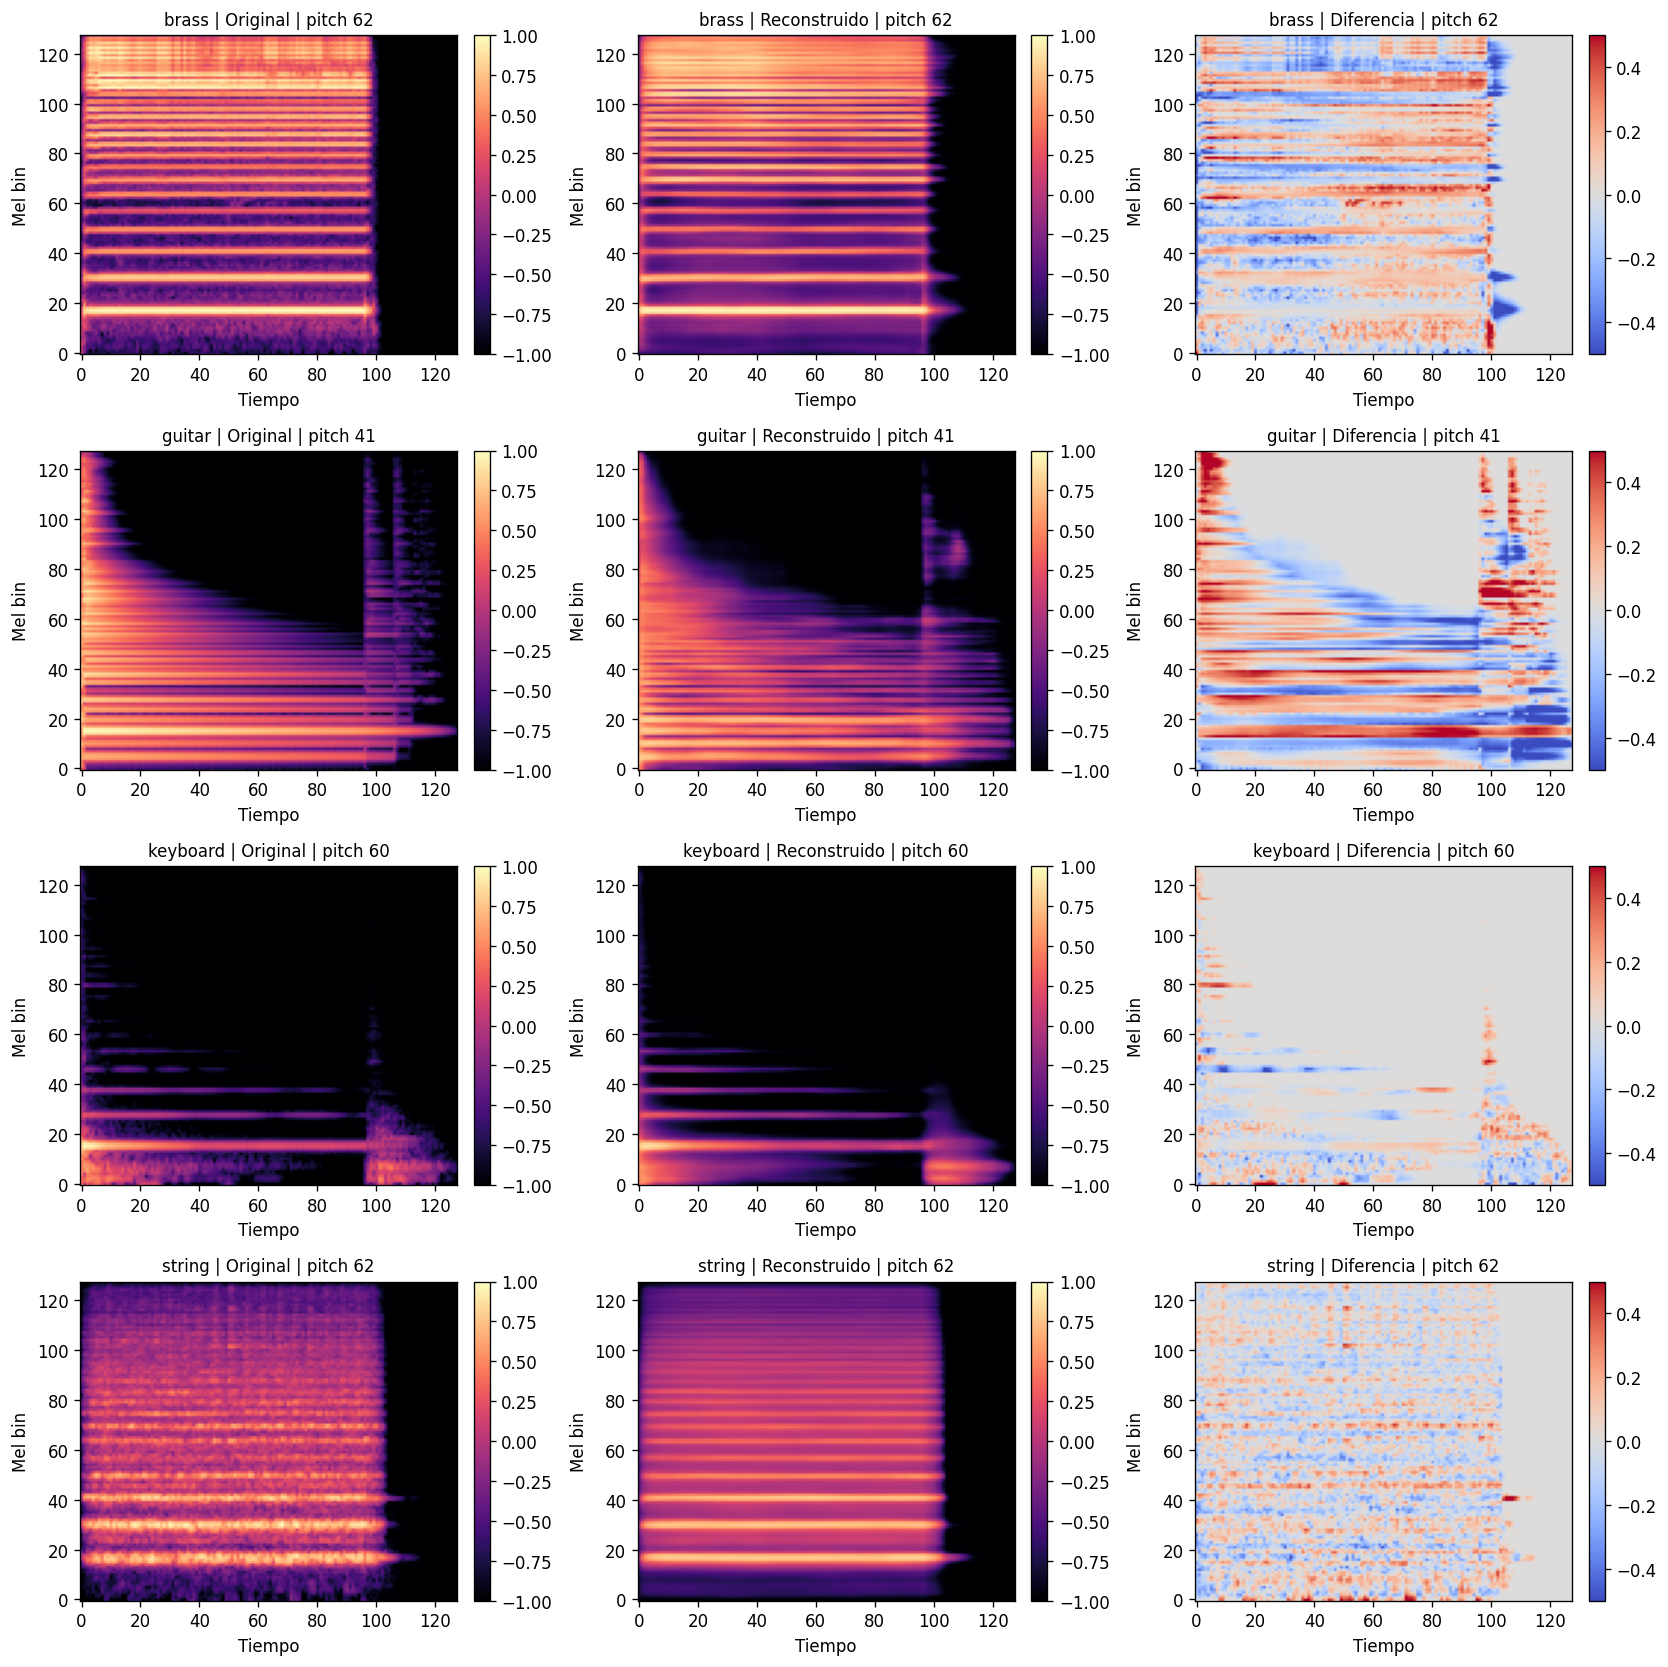

In [11]:
@torch.no_grad()
def reconstruir(model, loader):
    model.eval()
    origs, recs, fams, pits = [], [], [], []
    for xb, fb, pb in tqdm(loader, desc='Reconstruyendo valid', leave=False):
        xb = xb.to(device, non_blocking=True)
        fb = fb.to(device, non_blocking=True)
        pb = pb.to(device, non_blocking=True)
        with torch.cuda.amp.autocast(enabled=use_amp):
            mu, _ = model.encode(xb, fb, pb)
            rec = model.decode(mu, fb, pb)
        origs.append(xb.float().cpu())
        recs.append(rec.float().cpu())
        fams.append(fb.cpu())
        pits.append(pb.cpu())
    return torch.cat(origs), torch.cat(recs), torch.cat(fams), torch.cat(pits)


Xv_orig, Xv_rec, yv, pv = reconstruir(model, loader_val)
print(f'[INFO] Reconstrucciones: {tuple(Xv_rec.shape)}')

l1 = F.l1_loss(Xv_rec, Xv_orig, reduction='none').mean(dim=(1, 2, 3))
mse = F.mse_loss(Xv_rec, Xv_orig, reduction='none').mean(dim=(1, 2, 3))
l2_rel = torch.norm((Xv_orig - Xv_rec).flatten(1), dim=1) / (
    torch.norm(Xv_orig.flatten(1), dim=1) + 1e-8
)

df_recon = pd.DataFrame({
    'family': yv.numpy(),
    'l1': l1.numpy(),
    'mse': mse.numpy(),
    'l2_rel': l2_rel.numpy(),
})
tabla_recon = df_recon.groupby('family').mean()
tabla_recon.index = [FAMILY_NAMES[int(i)] for i in tabla_recon.index]
print('[INFO] Métricas de reconstrucción por familia (VALID):')
print(tabla_recon.round(5).to_string())
print(f'[INFO] Global: L1={l1.mean():.5f} | MSE={mse.mean():.5f} | L2rel={l2_rel.mean():.5f}')

fig, axes = plt.subplots(NUM_FAMILIES, 3, figsize=(14, 14), dpi=120)
for row, f in enumerate(range(NUM_FAMILIES)):
    idx = (yv == f).nonzero(as_tuple=True)[0]
    i = idx[0].item()
    orig = Xv_orig[i, 0].numpy()
    rec = Xv_rec[i, 0].numpy()
    diff = orig - rec
    paneles = [
        (orig, 'Original', 'magma', -1, 1),
        (rec, 'Reconstruido', 'magma', -1, 1),
        (diff, 'Diferencia', 'coolwarm', -0.5, 0.5),
    ]
    for col, (data, titulo, cmap, vmin, vmax) in enumerate(paneles):
        ax = axes[row, col]
        im = ax.imshow(data, origin='lower', aspect='auto', cmap=cmap, vmin=vmin, vmax=vmax)
        ax.set_title(f'{FAMILY_NAMES[f]} | {titulo} | pitch {int(pv[i])}', fontsize=10)
        ax.set_xlabel('Tiempo'); ax.set_ylabel('Mel bin')
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'reconstrucciones_valid.png', dpi=120, bbox_inches='tight')
plt.show()

## 12. Generación desde el prior

### ¿Qué se hace a continuación?
Se generan muestras nuevas con `z ~ N(0, I)` para un conjunto fijo de condiciones:
- 4 familias × 5 pitches (`36, 48, 60, 72, 84`) × 4 semillas (`42, 43, 44, 45`) = **80 muestras**.
Se guardan en `muestras_generadas.npz` y se grafica una grilla con la primera semilla.

### ¿Por qué se hace?
El conjunto fijo es el insumo del notebook de evaluación final: todos los modelos (VAE, Flow Matching, baseline) se compararán sobre las mismas condiciones y semillas. Guardar el `.npz` permite que el juez AST evalúe estas muestras después sin reentrenar nada. La grilla es la inspección visual mínima: si las muestras son todas iguales o ruido, se detecta acá.

[INFO] Muestras generadas: (80, 1, 128, 128) | rango=[-1.000, 0.947] | finite=True
[INFO] Guardado: /kaggle/working/vae_output/muestras_generadas.npz


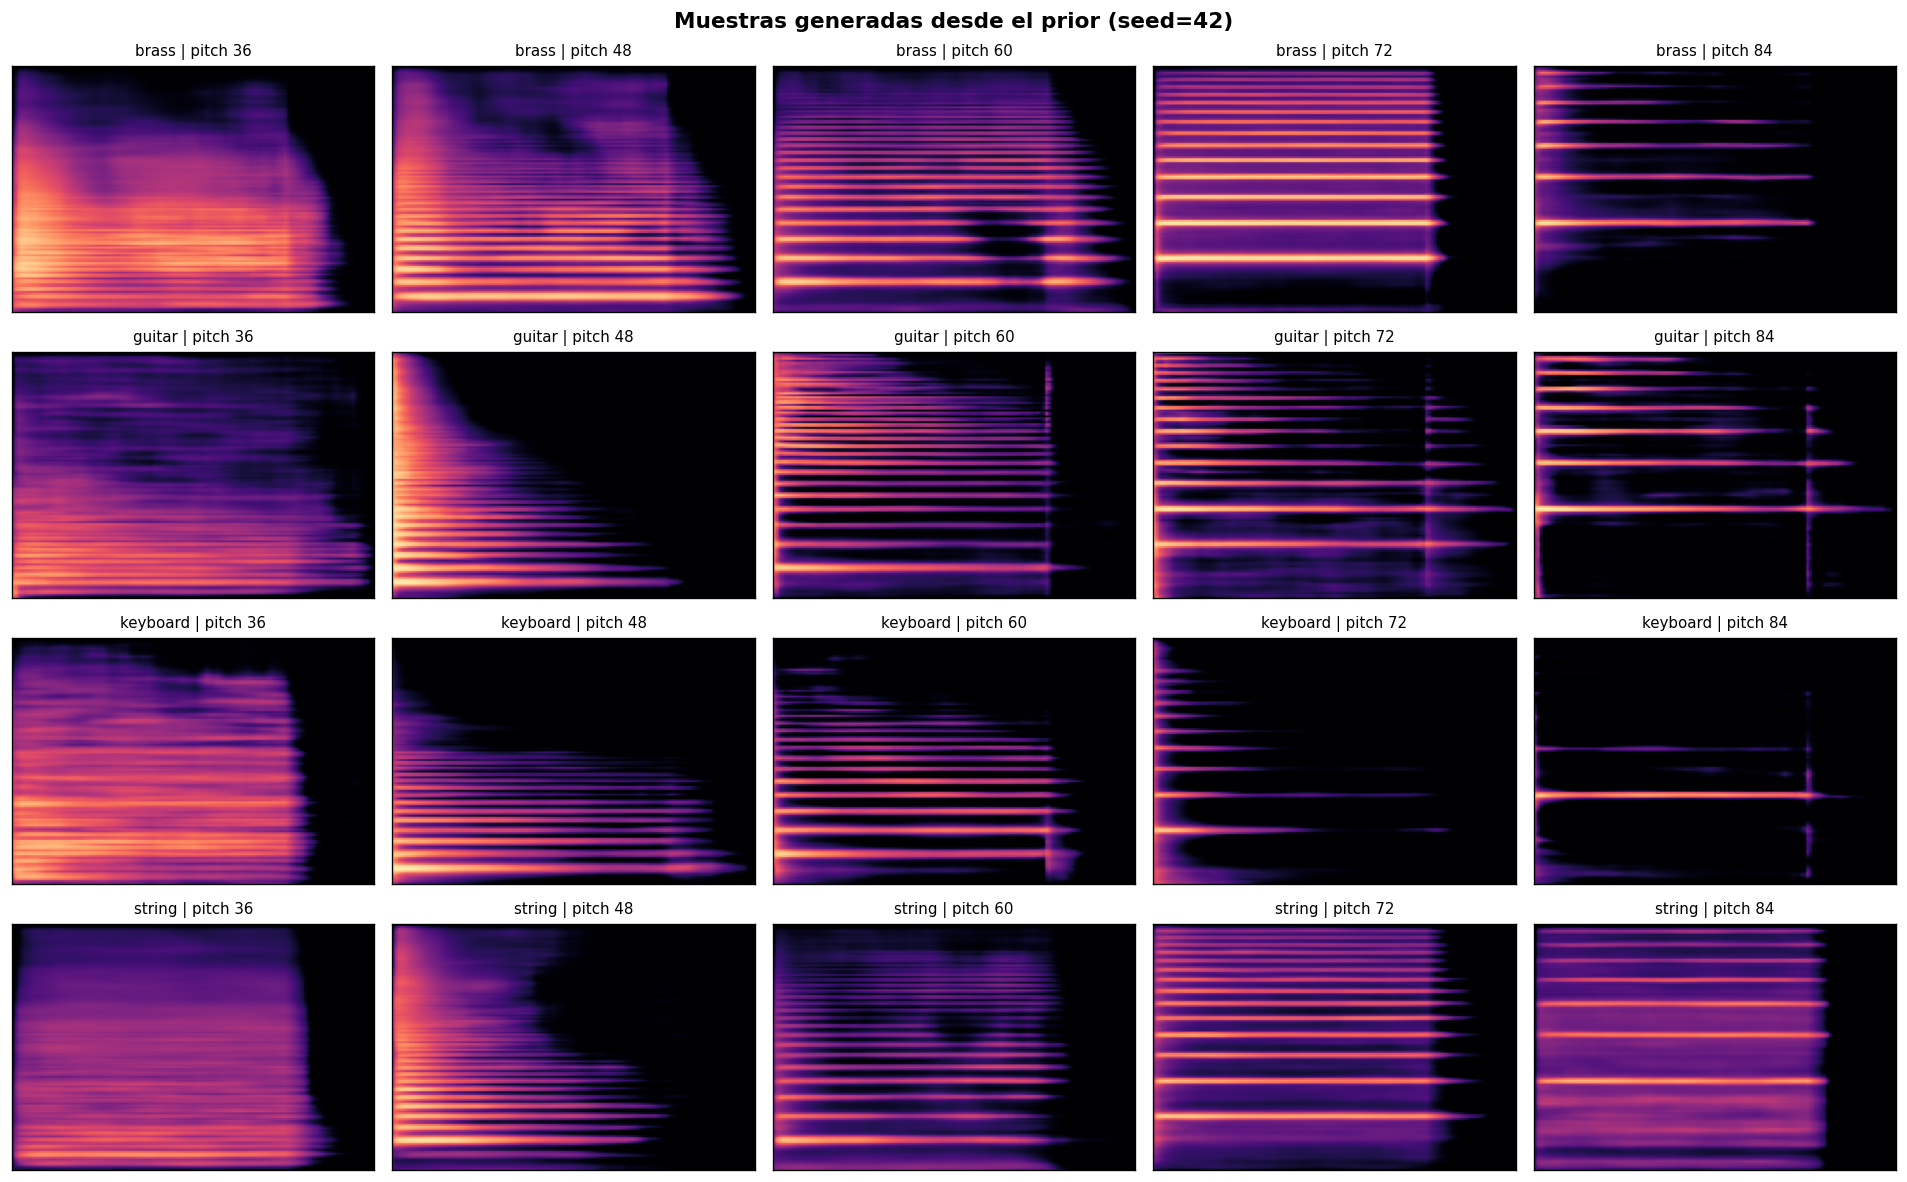

In [12]:
GEN_PITCHES = [36, 48, 60, 72, 84]
GEN_SEEDS = [42, 43, 44, 45]

@torch.no_grad()
def generar(model, families, pitches, seed):
    torch.manual_seed(seed)
    z = torch.randn(len(families), LATENT_DIM, device=device)
    f = torch.tensor(families, dtype=torch.long, device=device)
    p = torch.tensor(pitches, dtype=torch.long, device=device)
    with torch.cuda.amp.autocast(enabled=use_amp):
        mels = model.decode(z, f, p)
    return mels.float().cpu()


all_mels, all_f, all_p, all_s = [], [], [], []
for seed in GEN_SEEDS:
    fams = [f for f in range(NUM_FAMILIES) for _ in GEN_PITCHES]
    pits = [p for _ in range(NUM_FAMILIES) for p in GEN_PITCHES]
    mels = generar(model, fams, pits, seed)
    all_mels.append(mels)
    all_f.extend(fams)
    all_p.extend(pits)
    all_s.extend([seed] * len(fams))

gen_mels = torch.cat(all_mels, dim=0)
gen_f = torch.tensor(all_f, dtype=torch.long)
gen_p = torch.tensor(all_p, dtype=torch.long)
gen_seeds = torch.tensor(all_s, dtype=torch.long)

print(f'[INFO] Muestras generadas: {tuple(gen_mels.shape)} | '
      f'rango=[{gen_mels.min():.3f}, {gen_mels.max():.3f}] | '
      f'finite={torch.isfinite(gen_mels).all().item()}')

np.savez_compressed(
    OUTPUT_DIR / 'muestras_generadas.npz',
    mels=gen_mels.numpy().astype(np.float32),
    families=gen_f.numpy().astype(np.int64),
    pitches=gen_p.numpy().astype(np.int64),
    seeds=gen_seeds.numpy().astype(np.int64),
)
print(f'[INFO] Guardado: {OUTPUT_DIR / "muestras_generadas.npz"}')

mask = (gen_seeds == GEN_SEEDS[0])
fig, axes = plt.subplots(NUM_FAMILIES, len(GEN_PITCHES), figsize=(16, 10), dpi=120)
for r, f in enumerate(range(NUM_FAMILIES)):
    for c, p in enumerate(GEN_PITCHES):
        idx = ((gen_f == f) & (gen_p == p) & mask).nonzero(as_tuple=True)[0][0]
        ax = axes[r, c]
        ax.imshow(gen_mels[idx, 0].numpy(), origin='lower', aspect='auto',
                  cmap='magma', vmin=-1, vmax=1)
        ax.set_title(f'{FAMILY_NAMES[f]} | pitch {p}', fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
plt.suptitle(f'Muestras generadas desde el prior (seed={GEN_SEEDS[0]})',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'muestras_generadas.png', dpi=120, bbox_inches='tight')
plt.show()

## 13. Ejemplos de escucha: real vs reconstruido vs generado

### ¿Qué se hace a continuación?
Para una muestra de `valid` de cada familia se arma un trío con la **misma condición** `(familia, pitch)`, usando el pitch de `valid` más cercano a 60 para que las cuatro familias queden en un registro comparable:
1. mel real → Griffin-Lim;
2. mel real → encoder → decoder → Griffin-Lim;
3. `z ~ N(0, I)` + condición → decoder → Griffin-Lim.

Se guardan los WAVs en `vae_output/audio/`, se arma un ZIP y se muestran reproductores inline. También se grafica el trío de espectrogramas.

### ¿Por qué se hace?
Las métricas no alcanzan para saber si algo “suena a instrumento”. Escuchar el control real, la reconstrucción y la generación con el mismo vocoder permite separar tres fuentes de error: la pérdida del mel, la del decoder y la del Griffin-Lim. Los WAVs quedan como evidencia para el informe y para la escucha a ciegas.


--- BRASS | pitch 70 ---
1) Real (mel real -> Griffin-Lim):


2) Reconstruido (VAE):


3) Generado (prior):



--- GUITAR | pitch 70 ---
1) Real (mel real -> Griffin-Lim):


2) Reconstruido (VAE):


3) Generado (prior):


... (2 outputs left out)

3) Generado (prior):



--- STRING | pitch 70 ---
1) Real (mel real -> Griffin-Lim):


2) Reconstruido (VAE):


3) Generado (prior):


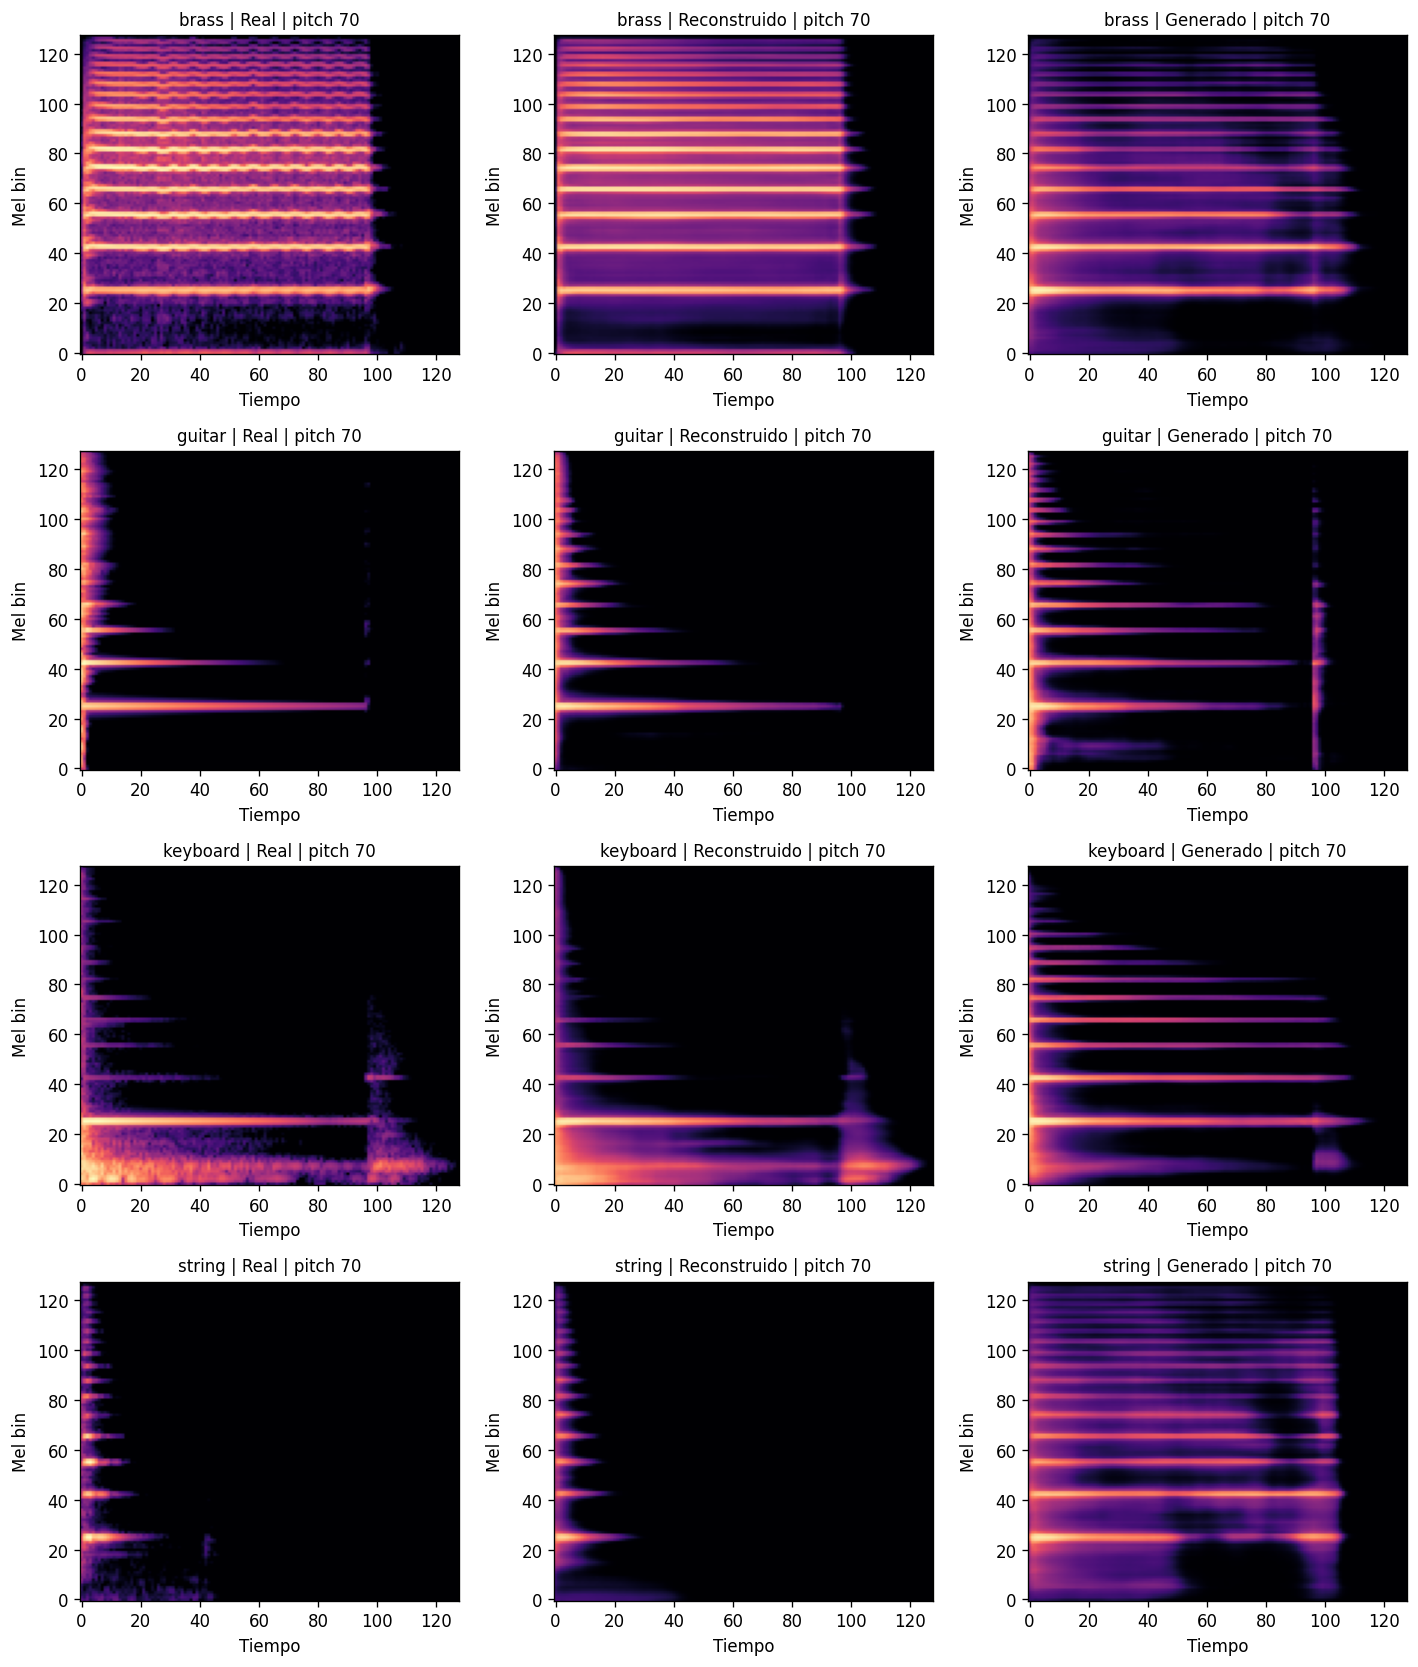

[INFO] ZIP de audios: /kaggle/working/vae_output/audio_ejemplos.zip


In [19]:
LISTEN_SEED = 42
ejemplos_audio = []

# limpiar WAVs de corridas anteriores para no mezclar versiones de audio
for p in AUDIO_DIR.glob('*.wav'):
    p.unlink()

for f in range(NUM_FAMILIES):
    idx_f = (yv == f).nonzero(as_tuple=True)[0]
    pitches_f = pv[idx_f]
    # pitch más cercano a 60: registro medio y comparable entre familias
    p_use = int(pitches_f[(pitches_f - 70).abs().argmin()].item())

    idx = idx_f[pv[idx_f] == p_use]
    i = idx[0].item()

    real_mel = Xv_orig[i, 0].numpy()
    recon_mel = Xv_rec[i, 0].numpy()
    gen_mel = generar(model, [f], [p_use], LISTEN_SEED)[0, 0].numpy()

    wav_real = vocoder.mel_norm_to_audio(real_mel, n_iter=250)
    wav_recon = vocoder.mel_norm_to_audio(recon_mel, n_iter=250)
    wav_gen = vocoder.mel_norm_to_audio(gen_mel, n_iter=250)

    nombre = FAMILY_NAMES[f]
    sf.write(AUDIO_DIR / f'real_{nombre}_p{p_use}.wav', wav_real, SR, subtype='PCM_16')
    sf.write(AUDIO_DIR / f'recon_{nombre}_p{p_use}.wav', wav_recon, SR, subtype='PCM_16')
    sf.write(AUDIO_DIR / f'gen_{nombre}_p{p_use}_s{LISTEN_SEED}.wav', wav_gen, SR, subtype='PCM_16')

    ejemplos_audio.append({
        'family': f, 'pitch': p_use,
        'real': real_mel, 'recon': recon_mel, 'gen': gen_mel,
    })

    print(f'\n--- {nombre.upper()} | pitch {p_use} ---')
    print('1) Real (mel real -> Griffin-Lim):')
    ipd.display(ipd.Audio(wav_real, rate=SR))
    print('2) Reconstruido (VAE):')
    ipd.display(ipd.Audio(wav_recon, rate=SR))
    print('3) Generado (prior):')
    ipd.display(ipd.Audio(wav_gen, rate=SR))

fig, axes = plt.subplots(len(ejemplos_audio), 3, figsize=(12, 14), dpi=120)
for row, ej in enumerate(ejemplos_audio):
    for col, (key, titulo) in enumerate([
        ('real', 'Real'), ('recon', 'Reconstruido'), ('gen', 'Generado'),
    ]):
        ax = axes[row, col]
        ax.imshow(ej[key], origin='lower', aspect='auto', cmap='magma', vmin=-1, vmax=1)
        ax.set_title(f'{FAMILY_NAMES[ej["family"]]} | {titulo} | pitch {ej["pitch"]}',
                     fontsize=10)
        ax.set_xlabel('Tiempo'); ax.set_ylabel('Mel bin')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'comparativa_mels_escucha.png', dpi=120, bbox_inches='tight')
plt.show()

with zipfile.ZipFile(OUTPUT_DIR / 'audio_ejemplos.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for p in sorted(AUDIO_DIR.glob('*.wav')):
        z.write(p, arcname=p.name)
print(f'[INFO] ZIP de audios: {OUTPUT_DIR / "audio_ejemplos.zip"}')

In [14]:
for ej in ejemplos_audio:
    m = ej['real']
    print(f"familia {ej['family']} | pitch {ej['pitch']} | mel real: media={m.mean():.4f} std={m.std():.4f}")

familia 0 | pitch 60 | mel real: media=-0.7337 std=0.4137
familia 1 | pitch 60 | mel real: media=-0.8132 std=0.3986
familia 2 | pitch 60 | mel real: media=-0.8562 std=0.3204
familia 3 | pitch 60 | mel real: media=-0.8874 std=0.2845


## 14. Métricas objetivas sin juez

### ¿Qué se hace a continuación?
Se calculan métricas que **no dependen del clasificador AST**:
- **Error de pitch**: se estima la F0 del audio generado con `librosa.pyin`, se convierte a MIDI y se compara con el pitch pedido (error absoluto en semitonos y porcentaje dentro de ±1 semitono).
- **Baseline media**: para cada `(familia, pitch)` se usa el mel promedio de `train`; se calcula su error de pitch y su diversidad (0 por definición).
- **Diversidad**: diferencia absoluta media por píxel entre pares de muestras generadas con la misma condición, comparada con muestras reales de `valid` (0 = todas iguales; 2 = máximo contraste).
- **Fréchet mel-lite**: distancia de Fréchet sobre 14 features mel (energía por bandas, centroide, rolloff) entre generado y real emparejado.

### ¿Por qué se hace?
El juez mide “familia”, pero no dice nada sobre si la nota tiene la altura pedida ni sobre si el modelo colapsó a la media. Estas métricas cubren justamente eso y permiten comparar VAE contra baseline sin depender de otro modelo. La distancia tipo FID es una versión reducida de la métrica de la sección 8; la versión completa, sobre embeddings del juez, va en el notebook del torneo.

In [15]:
def estimar_pitch_midi(wav, sr=SR):
    f0, voiced, _ = librosa.pyin(
        np.asarray(wav, dtype=np.float32),
        fmin=librosa.midi_to_hz(PITCH_MIN),
        fmax=librosa.midi_to_hz(PITCH_MAX + 6),
        sr=sr, frame_length=N_FFT, hop_length=HOP,
    )
    if f0 is None:
        return np.nan
    tiempos = librosa.times_like(f0, sr=sr, hop_length=HOP)
    mask = voiced & np.isfinite(f0) & (tiempos >= 0.15) & (tiempos <= 2.5)
    if mask.sum() == 0:
        mask = voiced & np.isfinite(f0)
    if mask.sum() == 0:
        return np.nan
    f_med = float(np.median(f0[mask]))
    return float(69.0 + 12.0 * np.log2(f_med / 440.0))


print('[INFO] Estimando pitch de las muestras generadas...')
pitch_gen = []
for i in tqdm(range(len(gen_mels)), desc='Pitch VAE', leave=False):
    wav = vocoder.mel_norm_to_audio(gen_mels[i, 0].numpy(), n_iter=64)
    pitch_gen.append(estimar_pitch_midi(wav))
pitch_gen = np.asarray(pitch_gen)
err_gen = np.abs(pitch_gen - gen_p.numpy().astype(np.float64))

# ── Baseline media por (familia, pitch) ─────────────────────────────────────
condiciones = sorted(set(zip(gen_f.tolist(), gen_p.tolist())))

def media_condicion(f, p):
    mask = (y_train == f) & (p_train == p)
    if mask.sum() >= 5:
        return X_train[mask].mean(dim=0)
    return X_train[y_train == f].mean(dim=0)

print(f'[INFO] Calculando baseline media para {len(condiciones)} condiciones...')
medias = {c: media_condicion(*c) for c in condiciones}
baseline_mels = torch.stack([medias[(int(f), int(p))] for f, p in zip(gen_f, gen_p)])

pitch_base = []
for c in tqdm(condiciones, desc='Pitch baseline', leave=False):
    wav = vocoder.mel_norm_to_audio(medias[c][0].numpy(), n_iter=64)
    pitch_base.append(estimar_pitch_midi(wav))
pitch_base_map = dict(zip(condiciones, pitch_base))
pitch_base = np.asarray([pitch_base_map[(int(f), int(p))] for f, p in zip(gen_f, gen_p)])
err_base = np.abs(pitch_base - gen_p.numpy().astype(np.float64))

# ── Diversidad ──────────────────────────────────────────────────────────────
def diversidad_l1(mels):
    """Diferencia absoluta media por píxel entre pares de muestras (0 a 2)."""
    if len(mels) < 2:
        return float('nan')
    flat = mels.flatten(1)
    d = torch.cdist(flat, flat, p=1)
    n = len(flat)
    return float(d.sum().item() / (n * (n - 1) * flat.shape[1]))

div_gen = float(np.nanmean([
    diversidad_l1(gen_mels[(gen_f == f) & (gen_p == p)]) for f, p in condiciones
]))

div_real_list = []
for f, p in condiciones:
    idx = ((yv == f) & (pv == p)).nonzero(as_tuple=True)[0][:4]
    if len(idx) >= 2:
        div_real_list.append(diversidad_l1(Xv_orig[idx]))
div_real = float(np.nanmean(div_real_list)) if div_real_list else float('nan')

# ── Real emparejado por condición ───────────────────────────────────────────
matched = []
for f, p in zip(gen_f.tolist(), gen_p.tolist()):
    idx = ((yv == f) & (pv == p)).nonzero(as_tuple=True)[0]
    if len(idx) == 0:
        idx_f = (yv == f).nonzero(as_tuple=True)[0]
        idx = idx_f[(pv[idx_f] - p).abs().argmin()].view(1)
    matched.append(Xv_orig[idx[0]])
matched = torch.stack(matched)

# ── Features mel y distancia de Fréchet ─────────────────────────────────────
def features_mel(mels):
    x = mels[:, 0]
    feats = []
    for b in torch.chunk(x, 4, dim=1):
        feats.append(b.mean(dim=(1, 2)))
        feats.append(b.std(dim=(1, 2)))
    freqs = torch.linspace(0, 1, x.shape[1]).view(1, x.shape[1], 1)
    energy = (x + 1.0).clamp(min=0)
    total = energy.sum(dim=1) + 1e-8
    centroid = (energy * freqs).sum(dim=1) / total
    feats.append(centroid.mean(dim=1))
    feats.append(centroid.std(dim=1))
    cum = torch.cumsum(energy, dim=1)
    thr = 0.85 * cum[:, -1:, :]
    rolloff = (cum < thr).sum(dim=1).float() / x.shape[1]
    feats.append(rolloff.mean(dim=1))
    feats.append(rolloff.std(dim=1))
    feats.append(energy.mean(dim=(1, 2)))
    feats.append(energy.std(dim=(1, 2)))
    return torch.stack(feats, dim=1).numpy()

from scipy.linalg import sqrtm

def frechet_distance(a, b):
    mu1, mu2 = a.mean(0), b.mean(0)
    C1 = np.cov(a, rowvar=False) + 1e-6 * np.eye(a.shape[1])
    C2 = np.cov(b, rowvar=False) + 1e-6 * np.eye(b.shape[1])
    covmean = sqrtm(C1 @ C2)
    if np.iscomplexobj(covmean):
        covmean = covmean.real
    return float(np.sum((mu1 - mu2) ** 2) + np.trace(C1 + C2 - 2 * covmean))

f_real = features_mel(matched)
f_gen = features_mel(gen_mels)
f_base = features_mel(baseline_mels)
fd_gen = frechet_distance(f_gen, f_real)
fd_base = frechet_distance(f_base, f_real)

metricas_gen = {
    'n_muestras': int(len(gen_mels)),
    'vae': {
        'pitch_mae_st': float(np.nanmean(err_gen)),
        'pitch_medae_st': float(np.nanmedian(err_gen)),
        'pct_dentro_1_st': float(np.nanmean(err_gen <= 1.0)),
        'diversidad_l1': div_gen,
        'frechet_mel_lite': fd_gen,
    },
    'baseline_media': {
        'pitch_mae_st': float(np.nanmean(err_base)),
        'pitch_medae_st': float(np.nanmedian(err_base)),
        'pct_dentro_1_st': float(np.nanmean(err_base <= 1.0)),
        'diversidad_l1': 0.0,
        'frechet_mel_lite': fd_base,
    },
    'real_matched': {
        'diversidad_l1': div_real,
    },
}

print('\n[INFO] ===== MÉTRICAS OBJETIVAS (sin juez) =====')
print(f'VAE            : pitch MAE={metricas_gen["vae"]["pitch_mae_st"]:.2f} st | '
      f'±1st={metricas_gen["vae"]["pct_dentro_1_st"]*100:.1f}% | '
      f'div={div_gen:.4f} | FID-lite={fd_gen:.2f}')
print(f'Baseline media : pitch MAE={metricas_gen["baseline_media"]["pitch_mae_st"]:.2f} st | '
      f'±1st={metricas_gen["baseline_media"]["pct_dentro_1_st"]*100:.1f}% | '
      f'div=0.0000 | FID-lite={fd_base:.2f}')
print(f'Real valid     : diversidad={div_real:.4f}')

metricas_recon = {
    'l1': float(l1.mean()),
    'mse': float(mse.mean()),
    'l2_rel': float(l2_rel.mean()),
    'por_familia': tabla_recon.to_dict(orient='index'),
}

[INFO] Estimando pitch de las muestras generadas...


Pitch VAE:   0%|          | 0/80 [00:00<?, ?it/s]

[INFO] Calculando baseline media para 20 condiciones...


Pitch baseline:   0%|          | 0/20 [00:00<?, ?it/s]


[INFO] ===== MÉTRICAS OBJETIVAS (sin juez) =====
VAE            : pitch MAE=1.24 st | ±1st=93.8% | div=0.2299 | FID-lite=0.12
Baseline media : pitch MAE=0.07 st | ±1st=100.0% | div=0.0000 | FID-lite=0.28
Real valid     : diversidad=0.2424


## 15. Espacio latente

### ¿Qué se hace a continuación?
Se codifican 2.000 muestras de `valid` y se proyectan sus `μ` a 2D con PCA, coloreando por familia y por pitch.

### ¿Por qué se hace?
Si el condicionamiento funciona, el latente debería organizarse por familia y mostrar un gradiente por pitch. Si todas las familias están mezcladas y el pitch no varía, el decoder está ignorando la condición. Es una figura interpretable y muy útil para la defensa.

[INFO] Varianza explicada: 30.2%


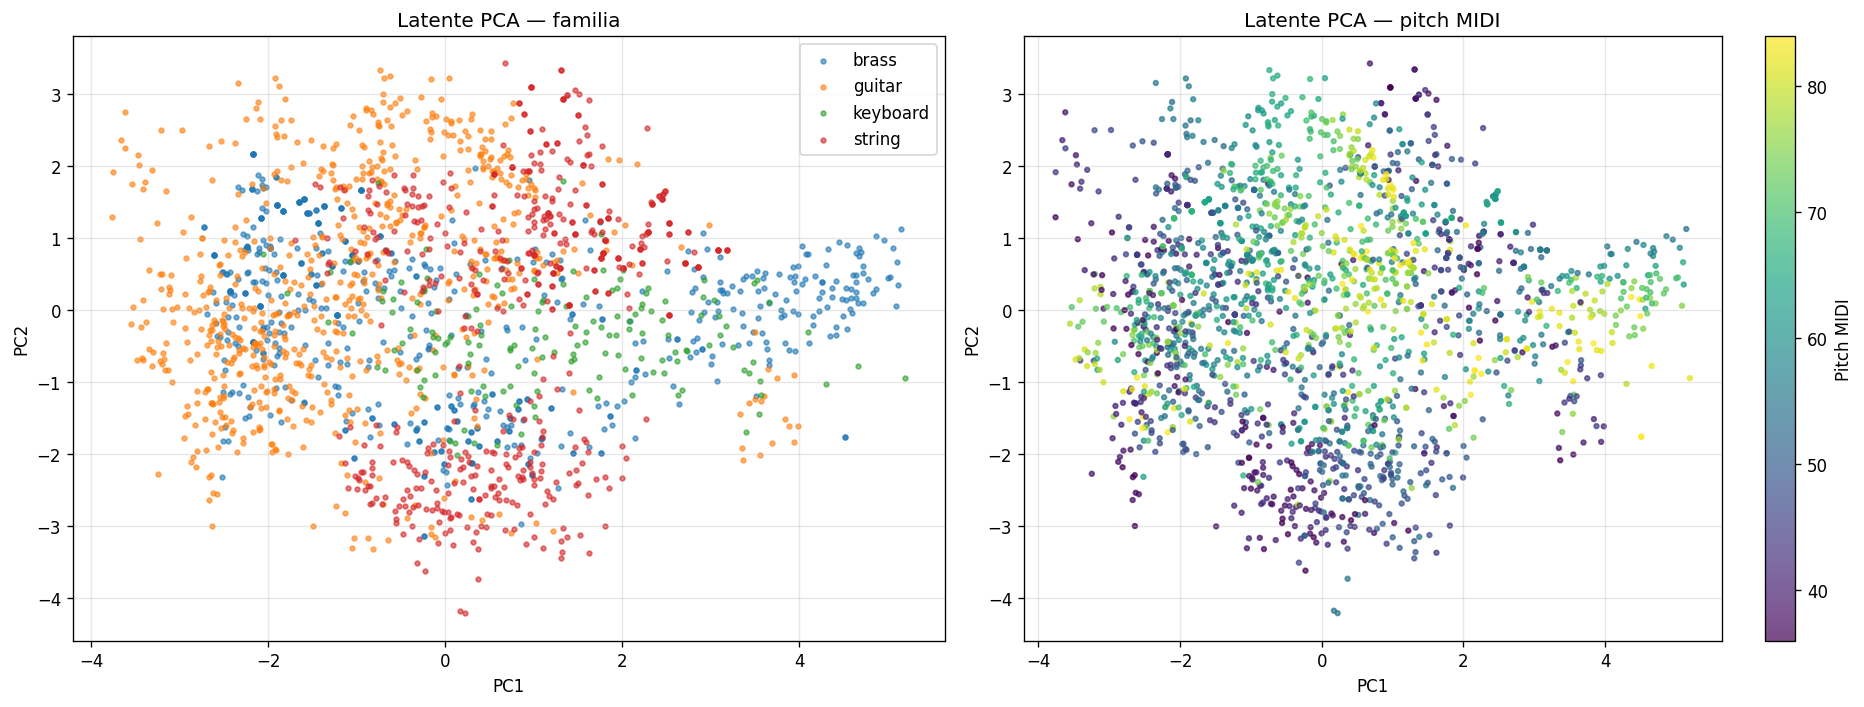

In [16]:
from sklearn.decomposition import PCA

n_lat = min(2000, len(X_val))
torch.manual_seed(SEED)
idx_lat = torch.randperm(len(X_val))[:n_lat]
mus = []
model.eval()
with torch.no_grad():
    for i in range(0, n_lat, 256):
        j = idx_lat[i:i + 256]
        mu, _ = model.encode(
            X_val[j].to(device), y_val[j].to(device), p_val[j].to(device)
        )
        mus.append(mu.float().cpu())
Z = torch.cat(mus).numpy()

pca = PCA(n_components=2, random_state=SEED)
Z2 = pca.fit_transform(Z)
print(f'[INFO] Varianza explicada: {pca.explained_variance_ratio_.sum()*100:.1f}%')

fig, axes = plt.subplots(1, 2, figsize=(16, 6), dpi=120)
for f in range(NUM_FAMILIES):
    m = (y_val[idx_lat].numpy() == f)
    axes[0].scatter(Z2[m, 0], Z2[m, 1], s=8, alpha=0.6, label=FAMILY_NAMES[f])
axes[0].set_title('Latente PCA — familia')
axes[0].set_xlabel('PC1'); axes[0].set_ylabel('PC2')
axes[0].legend(); axes[0].grid(alpha=0.3)

sc = axes[1].scatter(Z2[:, 0], Z2[:, 1], c=p_val[idx_lat].numpy(),
                     cmap='viridis', s=8, alpha=0.7)
axes[1].set_title('Latente PCA — pitch MIDI')
axes[1].set_xlabel('PC1'); axes[1].set_ylabel('PC2')
plt.colorbar(sc, ax=axes[1], label='Pitch MIDI')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'latentes_pca.png', dpi=120, bbox_inches='tight')
plt.show()

## 16. Inventario, métricas consolidadas y conclusiones

### ¿Qué se hace a continuación?
Se guarda `metricas_objetivas.json` con la configuración, las métricas de reconstrucción y de generación. Se lista el contenido de `vae_output/` y se imprime un resumen final.

### ¿Por qué se hace?
El notebook de evaluación final (torneo VAE vs Flow Matching vs baseline) necesita las muestras y las métricas en un formato estable, sin volver a entrenar. El inventario confirma que todos los artefactos quedaron escritos antes de cerrar la sesión de Kaggle.

In [17]:
metricas_final = {
    'config': config_actual,
    'reconstruccion': metricas_recon,
    'generacion': metricas_gen,
    'condiciones_generadas': {
        'pitches': GEN_PITCHES,
        'seeds': GEN_SEEDS,
        'familias': FAMILY_NAMES,
    },
    'nota': 'El juez AST se aplica en el notebook de evaluacion final (torneo). '
            'Aca no se usa para evitar fuga de criterio y ahorrar cuota.',
}

with open(OUTPUT_DIR / 'metricas_objetivas.json', 'w', encoding='utf-8') as f:
    json.dump(to_py(metricas_final), f, ensure_ascii=False, indent=2)

print(f'[INFO] Métricas guardadas en: {OUTPUT_DIR / "metricas_objetivas.json"}')
print(f'[INFO] Muestras generadas: {OUTPUT_DIR / "muestras_generadas.npz"}')
print(f'[INFO] Audios: {OUTPUT_DIR / "audio_ejemplos.zip"}')

print('\n[INFO] Archivos generados:')
print('-' * 70)
for archivo in sorted(OUTPUT_DIR.rglob('*')):
    if archivo.is_file():
        tam = archivo.stat().st_size / 1024
        rel = archivo.relative_to(OUTPUT_DIR)
        print(f'  {str(rel):<45} {tam:>9.1f} KB')
print('-' * 70)

print('\n[INFO] ===== RESUMEN NB03 =====')
print(f'  Épocas entrenadas     : {len(historial_df)}')
if len(historial_df) > 0:
    mejor = historial_df.loc[historial_df['val_recon'].idxmin()]
    print(f'  Mejor val_recon (L1)  : {mejor["val_recon"]:.5f} (epoch {int(mejor["epoch"])})')
    print(f'  Unidades activas      : {int(historial_df["active_units"].iloc[-1])}/{LATENT_DIM}')
    print(f'  Beta final            : {historial_df["beta"].iloc[-1]:.1e}')
print(f'  KL valid (mejor modelo): {kl_best:.1f} nats (objetivo {KL_TARGET:.0f})')
print(f'  Reconstrucción L1     : {metricas_recon["l1"]:.5f}')
print(f'  Pitch MAE VAE         : {metricas_gen["vae"]["pitch_mae_st"]:.2f} semitonos')
print(f'  Pitch MAE baseline    : {metricas_gen["baseline_media"]["pitch_mae_st"]:.2f} semitonos')
print(f'  Diversidad VAE        : {metricas_gen["vae"]["diversidad_l1"]:.4f}')
print(f'  Diversidad real       : {metricas_gen["real_matched"]["diversidad_l1"]:.4f}')
print(f'  FID-lite VAE          : {metricas_gen["vae"]["frechet_mel_lite"]:.2f}')
print(f'  FID-lite baseline     : {metricas_gen["baseline_media"]["frechet_mel_lite"]:.2f}')

print('\n[INFO] Próximo paso:')
print('  1. Revisar curvas, reconstrucciones y audios.')
print('  2. Descargar vae_output/ (o hacer Quick Save en Kaggle).')
print('  3. Usar muestras_generadas.npz en el notebook de Flow Matching (04)')
print('     y en el torneo final con el juez AST (05).')

[INFO] Métricas guardadas en: /kaggle/working/vae_output/metricas_objetivas.json
[INFO] Muestras generadas: /kaggle/working/vae_output/muestras_generadas.npz
[INFO] Audios: /kaggle/working/vae_output/audio_ejemplos.zip

[INFO] Archivos generados:
----------------------------------------------------------------------
  audio/gen_brass_p60_s42.wav                       125.0 KB
  audio/gen_guitar_p60_s42.wav                      125.0 KB
  audio/gen_keyboard_p60_s42.wav                    125.0 KB
  audio/gen_string_p60_s42.wav                      125.0 KB
  audio/real_brass_p60.wav                          125.0 KB
  audio/real_guitar_p60.wav                         125.0 KB
  audio/real_keyboard_p60.wav                       125.0 KB
  audio/real_string_p60.wav                         125.0 KB
  audio/recon_brass_p60.wav                         125.0 KB
  audio/recon_guitar_p60.wav                        125.0 KB
  audio/recon_keyboard_p60.wav                      125.0 KB
  audio/rec

## Conclusiones del Notebook 03

Con la ejecución completa se obtienen:

1. **C-VAE condicional entrenado** con familia + pitch, checkpoints y curvas.
2. **Reconstrucciones determinísticas** sobre `valid`, con métricas por familia.
3. **80 muestras generadas** desde el prior para condiciones y semillas fijas.
4. **Ejemplos de escucha** real / reconstruido / generado con el mismo Griffin-Lim.
5. **Métricas objetivas sin juez**: error de pitch, diversidad y distancia tipo FID.
6. **Espacio latente** en 2D para interpretar el condicionamiento.

El juez AST queda deliberadamente fuera de este notebook. En el notebook final se cargan `muestras_generadas.npz` (VAE), las muestras equivalentes de Flow Matching y las reales de `test`, y se evalúan todas con el mismo juez y el mismo protocolo.

**Siguiente paso:** `04_generador_flow_matching.ipynb`.

In [18]:
print((X_train >= 0.999).float().mean().item())

6.813897198298946e-05
